# For Daunt
by **Hogg** (NYU)

**Restart and Run All** this notebook. Then:
- The rv data are `est_rvs`; shape `(num_chunks, num_epochs)`.
- The reported uncertainties on these rv measurements are `reported_sigmas`.
- The true rv values that you are trying to estimate (up to an offset) are `true_epoch_rvs`.

Don't look too carefully at this code; it will give you (bad) ideas.

In [1]:
import numpy as np
import sys
sys.path.append('..')
# import jabble.quickplay
import astropy.units as u
import matplotlib.pyplot as plt

In [2]:
import datetime
import os
today = datetime.date.today()
out_dir = os.path.join('/scratch/mdd423/wobble_jax','out',today.strftime("%y-%m-%d"))
os.makedirs(out_dir,exist_ok=True)

In [3]:
rng = np.random.default_rng(17)
print(rng)

Generator(PCG64)


In [4]:
num_epochs = 60
year = 365.26
times = rng.uniform(0,3. * year, num_epochs)
bc_approx = 3.e4 * np.sin(2. * np.pi * times / year)

star_amplitude = 5.
star_period = 0.433 * year
eprv = star_amplitude * np.sin(2. * np.pi * times / star_period)
true_epoch_rvs = bc_approx + eprv
print(true_epoch_rvs.shape)

(60,)


In [5]:
num_chunks = 45
o_min = -100
o_max = 100
chunk_offsets = rng.uniform(o_min,o_max,num_chunks)
print(chunk_offsets.shape)

(45,)


In [6]:
bad_chunks = 2
bad_chunk_ind = rng.choice(num_chunks, bad_chunks)

bad_epochs = 2
bad_epoch_ind = rng.choice(num_epochs, bad_epochs)

bad_chunks_2 = 2
bad_chunk_ind_2 = rng.choice(num_chunks, bad_chunks)

bad_epochs_2 = 2
bad_epoch_ind_2 = rng.choice(num_epochs,bad_epochs)

bad_both = 120
xy = np.mgrid[:num_chunks, :num_epochs].reshape(2, -1).T
bad_both_ind = xy.take(rng.choice(xy.shape[0], bad_both, replace=False), axis=0)

bad_both_2 = 120
xy = np.mgrid[:num_chunks, :num_epochs].reshape(2, -1).T
bad_both_ind_2 = xy.take(rng.choice(xy.shape[0], bad_both_2, replace=False), axis=0)

In [7]:
epoch_vars = rng.normal(2, 0.5, size=(num_epochs)) ** 2
chunk_vars = rng.normal(2, 0.5, size=(num_chunks)) ** 2
reported_sigmas = np.sqrt(epoch_vars[None, :] + chunk_vars[:, None] + rng.normal(2, 0.5, size=(num_chunks, num_epochs)) ** 2)
sigmas = 1.1 * reported_sigmas
sigmas[bad_chunk_ind,:] = np.abs(rng.normal(0, 30,size=(bad_chunks, num_epochs)))
sigmas[:,bad_epoch_ind] = np.abs(rng.normal(0, 30,size=(num_chunks,bad_epochs)))
sigmas[bad_both_ind[:,0],bad_both_ind[:,1]] = np.abs(rng.normal(0,10,size=bad_both))
print(sigmas.shape)

(45, 60)


In [8]:
# make rvs
est_rvs = true_epoch_rvs[None,:] + chunk_offsets[:,None]
print(est_rvs.shape)

(45, 60)


In [9]:
# bias the rvs in bad ways
est_rvs[bad_chunk_ind_2,:] += 20. * rng.uniform(size=(bad_chunks_2, num_epochs))
est_rvs[:,bad_epoch_ind_2] += 20. * rng.uniform(size=(num_chunks, bad_epochs_2))
est_rvs[bad_both_ind_2[:,0],bad_both_ind_2[:,1]] += 20. * rng.uniform(size=bad_both_2)

# add noise
est_rvs += rng.normal(0, sigmas, size=est_rvs.shape)
print(est_rvs.shape)

(45, 60)


bad data is useless. but inverse variance of 

In [10]:
import cmasher

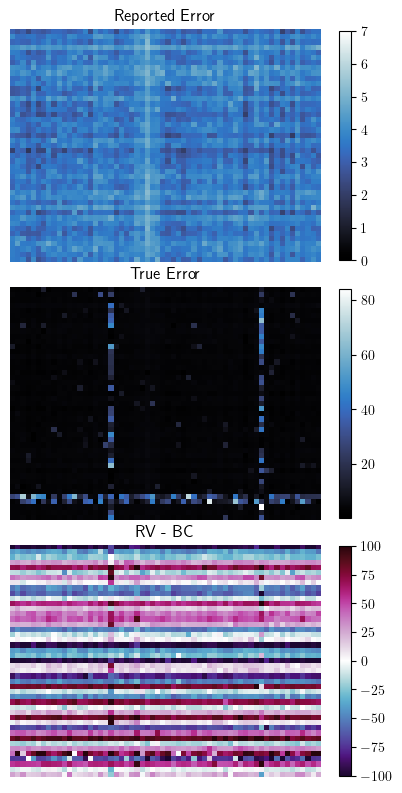

In [11]:
plt.rcParams.update({
    "text.usetex": True,
})

mappable = cmasher.arctic
fig,axes = plt.subplots((3),figsize=(5,10))
im1 = axes[0].imshow(reported_sigmas,cmap=mappable,vmin=0,vmax=7)
im2 = axes[1].imshow(sigmas,cmap=mappable)
im3 = axes[2].imshow(est_rvs - bc_approx,cmap=cmasher.viola,vmin=-100,vmax=100)
axes[0].axis('off')
axes[0].set_title('Reported Error')
axes[1].axis('off')
axes[1].set_title('True Error')
axes[2].axis('off')
axes[2].set_title('RV - BC')
plt.colorbar(im1,ax=axes[0],shrink=0.9)
plt.colorbar(im2,ax=axes[1],shrink=0.9)
plt.colorbar(im3,ax=axes[2],shrink=0.9)
plt.subplots_adjust(hspace=0.01)
plt.savefig(os.path.join(out_dir,'sim_data_summary.png'),dpi=200,bbox_inches='tight')
plt.show()

In [13]:
import sys
sys.path.append('..')
import jabble.quickplay

In [14]:
# rvs_total = est_rvs
# rvs_error_total = reported_sigmas
# rvs_clean = rvs_total - np.average(rvs_total[rvs_error_total > 0],weights=1/(rvs_error_total[rvs_error_total > 0])**2)
# rvs_comb, offsets, rvs_comb_info, offsets_info, reweight = \
#     jabble.quickplay.irls_method(
#         rvs_clean,
#         rvs_error_total,
#         times,
#         Q=3, steps=20,
#         lambda_offsets=1e-8, lambda_rvs=1e-8,
#     )

In [15]:
def plot_rv_model_compare(
    axes,
    time1,          # shape (n_datasets, n_times) — observation times per dataset [MJD]
    rv_est,         # shape (n_datasets, n_times) — raw RV estimates [m/s]
    rv_est_err,     # shape (n_datasets, n_times) — raw RV errors [m/s]
    time_comb,      # shape (n_times,) — times for combined RV [MJD]
    rv_est_comb,    # shape (n_times,) — combined RV estimate [m/s]
    rv_err_comb,    # shape (n_times,) — combined RV error [m/s]
    time2,          # shape (n_times2,) — times for true RV [MJD]
    rv_true,             # shape (n_times2,) — true RV (sign-flipped when plotted) [m/s]
    period,         # astropy Quantity — orbital period [day]
    offset_param,   # shape (n_datasets,) — modeled offset per dataset [m/s]
    reweight_err,   # shape (n_datasets, n_times) — reweighted errors [m/s]
    bc,
    options
):
    """
    Produces a 2x2 grid of RV plots:

      Col 0 (Unmodeled)  |  Col 1 (Modeled)
      -------------------+------------------
      Row 0: EPRV        |  EPRV - offsets
        (RV - BC)        |  (RV - offset - BC)
      -------------------+------------------
      Row 1: Full RV     |  Full RV - offsets
        (no BC removal)  |  (RV - offset, no BC)

    Colours:
      black  — individual dataset points (per-row)
      red    — unmodeled combined RV  (left col)
      green  — true RV               (right col)
    """

    # ------------------------------------------------------------------ #
    #  Inner helper: mask bad values, compute BC, then errorbar on axes   #
    # ------------------------------------------------------------------ #
    def _plot_sub_rv(ax_pair, times, rv_q, rv_err_q, bc, mpl_options):
        """
        ax_pair : [ax_top, ax_bot]  (ax_top = EPRV/phase, ax_bot = full RV/time)
        times   : 1-D array of MJD floats
        rv_q    : astropy Quantity RV
        rv_err_q: astropy Quantity RV error
        """

        # -- mask NaN / Inf in RV or error --
        bad = (
            np.isnan(rv_q)  | np.isinf(rv_q) |
            np.isnan(rv_err_q) | np.isinf(rv_err_q)
        )
        ok = ~bad

        # ---- Row 0: precision RV  (RV - BC),  folded on period, in m/s ----
        eprv     = (rv_q[ok] - bc[ok])
        eprv_err = rv_err_q[ok]
        phase    = times[ok] % period

        ax_pair[0].errorbar(phase, eprv, yerr=eprv_err, **mpl_options)

        # ---- Row 1: full RV (no BC removal),  vs time,  in km/s -----------
        full_rv     = rv_q[ok]
        full_rv_err = rv_err_q[ok]

        # ax_pair[1].errorbar(times[ok], full_rv, yerr=full_rv_err, **mpl_options)

        return ax_pair

    # ------------------------------------------------------------------ #
    #  Axis labels & shared limits                                         #
    # ------------------------------------------------------------------ #
    period_d = period

    # Row 0: EPRV  (m/s)
    for col in range(2):
        axes[0, col].set_xlabel(f'Phase [d]  (P = {period_d:.2f} d)')
    axes[0, 0].set_ylabel('RV − BC  [m/s]')
    axes[0, 0].set_ylim(-options['rv_eprv_yrange1'] + options['rv_eprv_mid1'], options['rv_eprv_yrange1'] + options['rv_eprv_mid1'])
    axes[0, 1].set_ylim(-options['rv_eprv_yrange2'] + options['rv_eprv_mid2'], options['rv_eprv_yrange2'] + options['rv_eprv_mid2'])
    axes[0, 0].set_title('Raw EPRV',  fontsize=10)
    axes[0, 1].set_title('Minus Offset EPRV',     fontsize=10)
    axes[0, 2].set_title('Residual',     fontsize=10)


    # Row 1: full RV  (km/s)
    # for col in range(2):
    #     axes[1, col].set_xlabel('Time [MJD]')
    #     axes[1, col].set_ylabel('RV  [m/s]')
    # axes[1, 1].set_ylim(-options['rv_rv_yrange'], options['rv_rv_yrange'])
    # axes[1, 0].set_ylim(-options['rv_rv_yrange'], options['rv_rv_yrange'])
    # axes[1, 0].set_title('Raw RV',    fontsize=10)
    # axes[1, 1].set_title('Minus Offset RV',       fontsize=10)
    # axes[1, 2].set_title('Residual',       fontsize=10)


    # Col 2: full RV  (km/s)
    # for col in range(2):
    # axes[1, 2].set_xlabel('Time [MJD]')
    axes[0, 2].set_xlabel(f'Phase [d]  (P = {period_d:.2f} d)')


    # axes[0, 2].set_ylabel('RV - RV  [m/s]')
    # axes[1, 2].set_ylabel('RV - RV  [m/s]')
    # axes[1, 2].set_ylim(-options['rv_res_yrange'], options['rv_res_yrange'])
    axes[0, 2].set_ylim(-options['rv_res_yrange'], options['rv_res_yrange'])
    

    # ------------------------------------------------------------------ #
    #  Left column — raw (unmodeled) individual datasets                  #
    # ------------------------------------------------------------------ #
    indiv_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=4,
                      elinewidth=0.5, capsize=0)

    for i in range(rv_est.shape[0]):
        _plot_sub_rv(
            axes[:, 0],
            time1[i, :],
            rv_est[i, :],
            rv_est_err[i, :],
            bc,
            indiv_opts,
        )

    # ------------------------------------------------------------------ #
    #  Middle column — unmodeled combined RV  (red)                         #
    # ------------------------------------------------------------------ #
    comb_opts = dict(fmt='.r', alpha=0.85, ms=3, zorder=3,
                     elinewidth=0.7, capsize=1.5, label='Combined RV')
    _plot_sub_rv(
        axes[:, 1],
        time_comb,
        rv_est_comb,
        rv_err_comb,
        bc,
        comb_opts,
    )

    # ------------------------------------------------------------------ #
    #  Middle column — modeled (offset-subtracted) individual datasets     #
    # ------------------------------------------------------------------ #
    model_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=1,
                      elinewidth=0.5, capsize=0)

    for i in range(rv_est.shape[0]):
        _plot_sub_rv(
            axes[:, 1],
            time1[i, :],
            (rv_est[i, :] - offset_param[i]),
            reweight_err[i, :],
            bc,
            model_opts,
        )

    # ------------------------------------------------------------------ #
    #  Middle & Left column — true RV (green, sign-flipped as in original)        #
    # ------------------------------------------------------------------ #
    true_opts = dict(fmt='.g', alpha=0.85, ms=4, zorder=2,
                     elinewidth=0.5, capsize=0, label='True RV')
    # for i in range(2):
    _plot_sub_rv(
        axes[:, 0],
        time2,
        rv_true - np.mean(rv_true) + np.mean(rv_est),                                    # sign flip matches original
        np.ones(rv_true.shape),  # negligible error for true signal
        bc,
        true_opts,
    )

    _plot_sub_rv(
            axes[:, 1],
            time2,
            rv_true,                                    # sign flip matches original
            np.ones(rv_true.shape),  # negligible error for true signal
            bc,
            true_opts,
        )

    # ------------------------------------------------------------------ #
    #  Middle column — modeled (offset-subtracted) individual datasets     #
    # ------------------------------------------------------------------ #
    # model_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=1,
    #                   elinewidth=0.5, capsize=0)

    # for i in range(rv_est.shape[0]):
    #     _plot_sub_rv(
    #         axes[:, 1],
    #         time1[i, :],
    #         (rv_est[i, :] - offset_param[i]) * u.m / u.s,
    #         reweight_err[i, :] * u.m / u.s,
    #         bc,
    #         model_opts,
    #     )
    # ------------------------------------------------------------------ #
    #  Right column — unmodeled combined RV  (red)                         #
    # ------------------------------------------------------------------ #
    comb_opts = dict(fmt='.r', alpha=0.85, ms=3, zorder=3,
                     elinewidth=0.7, capsize=1.5, label='Combined RV')
    _plot_sub_rv(
        axes[:, 2],
        time_comb,
        np.zeros(rv_est_comb.shape),
        rv_err_comb,
        np.zeros(bc.shape),
        comb_opts,
    )
        
    # ------------------------------------------------------------------ #
    #  Right column — modeled (offset-subtracted) individual datasets     #
    # ------------------------------------------------------------------ #
    model_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=1,
                      elinewidth=0.5, capsize=0)

    for i in range(rv_est.shape[0]):
        _plot_sub_rv(
            axes[:, 2],
            time1[i, :],
            (rv_est[i, :] - offset_param[i] - rv_est_comb),
            reweight_err[i, :],
            np.zeros(bc.shape),
            model_opts,
        )

    # ------------------------------------------------------------------ #
    #  Right column — true RV (green, sign-flipped as in original)        #
    # ------------------------------------------------------------------ #
    # true_opts = dict(fmt='.g', alpha=0.85, ms=4, zorder=2,
    #                  elinewidth=0.5, capsize=0, label='True RV')
    # # for i in range(axes.shape[1]):
    # _plot_sub_rv(
    #     axes[:, 2],
    #     time2,
    #     -rv - rv_est_comb * u.m / u.s,                                    # sign flip matches original
    #     np.ones(rv.shape) * 0.01 * u.m / u.s,  # negligible error for true signal
    #     np.zeros(bc.shape) * bc.unit,
    #     true_opts,
    # )

    # ------------------------------------------------------------------ #
    #  Legends on right column                                             #
    # ------------------------------------------------------------------ #
    axes[0, 2].legend(fontsize=7, loc='upper right')
    # axes[1, 2].legend(fontsize=7, loc='upper right')

    return axes

def plot_offset_model_compare(
    axes,
    time1,          # shape (n_datasets, n_times) — observation times per dataset [MJD]
    rv_est,         # shape (n_datasets, n_times) — raw RV estimates [m/s]
    rv_est_err,     # shape (n_datasets, n_times) — raw RV errors [m/s]
    time_comb,      # shape (n_times,) — times for combined RV [MJD]
    rv_est_comb,    # shape (n_times,) — combined RV estimate [m/s]
    rv_err_comb,    # shape (n_times,) — combined RV error [m/s]
    time2,          # shape (n_times2,) — times for true RV [MJD]
    rv_true,             # shape (n_times2,) — true RV (sign-flipped when plotted) [m/s]
    period,         # astropy Quantity — orbital period [day]
    offset_param,   # shape (n_datasets,) — modeled offset per dataset [m/s]
    offset_param_err,
    reweight_err,   # shape (n_datasets, n_times) — reweighted errors [m/s]
    bc,
    options
):
    """
    Produces a 2x2 grid of RV plots:

      Col 0 (Unmodeled)  |  Col 1 (Modeled)
      -------------------+------------------
      Row 0: EPRV        |  EPRV - offsets
        (RV - BC)        |  (RV - offset - BC)
      -------------------+------------------
      Row 1: Full RV     |  Full RV - offsets
        (no BC removal)  |  (RV - offset, no BC)

    Colours:
      black  — individual dataset points (per-row)
      red    — unmodeled combined RV  (left col)

      green  — true RV               (right col)
    """
    # ------------------------------------------------------------------ #
    #  Inner helper: mask bad values, compute BC, then errorbar on axes   #
    # ------------------------------------------------------------------ #
    def _plot_sub_rv(ax_pair, times, rv_q, rv_err_q, bc, mpl_options):
        """
        ax_pair : [ax_top, ax_bot]  (ax_top = EPRV/phase, ax_bot = full RV/time)
        times   : 1-D array of MJD floats
        rv_q    : astropy Quantity RV
        rv_err_q: astropy Quantity RV error
        """

        # -- mask NaN / Inf in RV or error --
        bad = (
            np.isnan(rv_q)  | np.isinf(rv_q) |
            np.isnan(rv_err_q) | np.isinf(rv_err_q)
        )
        ok = ~bad

        # ---- Row 0: precision RV  (RV - BC),  folded on period, in m/s ----
        eprv     = (rv_q[ok] - bc[ok])
        eprv_err = rv_err_q[ok]
        chunk_index = np.arange(0,len(rv_q),step=1)
        # phase    = times[ok] % period.to(u.day).value

        ax_pair[0].errorbar(chunk_index[ok], eprv, yerr=eprv_err, **mpl_options)

        # ---- Row 1: full RV (no BC removal),  vs time,  in km/s -----------
        full_rv     = rv_q[ok]
        full_rv_err = rv_err_q[ok]

        ax_pair[1].errorbar(chunk_index[ok], full_rv, yerr=full_rv_err, **mpl_options)

        return ax_pair


    # ------------------------------------------------------------------ #
    #  Axis labels & shared limits                                         #
    # ------------------------------------------------------------------ #
    _,dummy_ax = plt.subplots(1)
    period_d = period

    # Row 0: EPRV  (m/s)
    axes[0, 0].set_ylabel('RV - BC [m/s]')
    axes[0, 0].set_ylim(options['offset_col1_mid']-options['offset_col1_yrange'], options['offset_col1_mid'] + options['offset_col1_yrange'])
    axes[0, 0].set_title('Raw EPRV',  fontsize=10)
    axes[0, 1].set_title('Minus Epoch EPRV',     fontsize=10)
    axes[0, 2].set_title('Residual',     fontsize=10)


    # Row 1: full RV  (m/s)
    axes[0, 1].set_ylim(options['offset_col2_mid']-options['offset_col2_yrange'], options['offset_col2_mid'] + options['offset_col2_yrange'])

    # Col 2: full RV  (m/s)
    for col in range(axes.shape[1]):
        axes[0, col].set_xlabel('Chunk Index')

    # axes[0, 2].set_ylabel('RV - RV  [m/s]')
    axes[0, 2].set_ylim(-options['offset_col3_yrange'], options['offset_col3_yrange'])
    

    # ------------------------------------------------------------------ #
    #  Left column — raw (unmodeled) individual datasets                  #
    # ------------------------------------------------------------------ #
    indiv_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=4,
                      elinewidth=0.5, capsize=0)

    for i in range(rv_est.shape[1]):

        _plot_sub_rv([axes[0, 0],dummy_ax],
            time1[:, i],
            rv_est[:, i] - bc[i],
            rv_est_err[:, i],
            np.ones((rv_est_err.shape[0])),
            indiv_opts,
        )

    # ------------------------------------------------------------------ #
    #  Middle column — unmodeled combined RV  (red)                         #
    # ------------------------------------------------------------------ #
    comb_opts = dict(fmt='.r', alpha=0.85, ms=3, zorder=3,
                     elinewidth=0.7, capsize=1.5, label='Offset Parameter')
    _plot_sub_rv(
        [axes[0, 1],dummy_ax],
        time_comb,
        offset_param,
        offset_param_err,
        np.zeros((rv_est_err.shape[0])),
        comb_opts,
    )

    # ------------------------------------------------------------------ #
    #  Middle column — modeled (RV-subtracted) individual datasets     #
    # ------------------------------------------------------------------ #
    model_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=1,
                      elinewidth=0.5, capsize=0)

    # print('RV - RV_param')
    for i in range(rv_est.shape[1]):
        # print(i,(rv_est[:, i] - rv_est_comb[i]).max() -  (rv_est[:, i] - rv_est_comb[i]).min())
        _plot_sub_rv(
            [axes[0, 1],dummy_ax],
            time1[:, i],

            (rv_est[:, i] - rv_est_comb[i]),
            reweight_err[:, i],
            np.zeros((rv_est_err.shape[0])),
            model_opts,
        )
    
    # ------------------------------------------------------------------ #
    #  Right column — unmodeled combined RV  (red)                         #
    # ------------------------------------------------------------------ #
    comb_opts = dict(fmt='.r', alpha=0.85, ms=3, zorder=3,
                     elinewidth=0.7, capsize=1.5, label='Offset Parameter')
    _plot_sub_rv(
        [axes[0, 2],dummy_ax],
        time_comb,
        np.zeros(offset_param.shape),
        offset_param_err,
        np.zeros(offset_param_err.shape),
        comb_opts,
    )
        
    # ------------------------------------------------------------------ #
    #  Right column — modeled (offset-subtracted) individual datasets     #
    # ------------------------------------------------------------------ #
    model_opts = dict(fmt='.k', alpha=0.15, ms=1.5, zorder=1,
                      elinewidth=0.5, capsize=0)

    # print('Residual')
    for i in range(rv_est.shape[1]):
        # print(i,(rv_est[:, i] - rv_est_comb[i]- offset_param).max() -  (rv_est[:, i] - rv_est_comb[i]).min())
        _plot_sub_rv(
            [axes[0, 2],dummy_ax],
            time1[:, i],
            (rv_est[:, i] - offset_param - rv_est_comb[i]),
            reweight_err[:, i],
            np.zeros(offset_param_err.shape),
            model_opts,

        )

    # ------------------------------------------------------------------ #
    #  Legends on right column                                             #
    # ------------------------------------------------------------------ #
    axes[0, 2].legend(fontsize=7, loc='upper right')
    return axes

In [41]:
def irls_method_jack_knife(rvs,err,time,steps,lambda_offsets=1e-5,lambda_rvs=1e-5,Q=3,n_sets=5):
    '''
    Iteratively Reweighted Least Squares Method for RV and Offset Estimation
    Parameters
    ----------
    rvs : array-like
        Radial velocities for each observation
    err : array-like
        Errors associated with each radial velocity measurement
    time : array-like
        Time of each observation
    steps : int
        Number of iterations for the IRLS method
    lambda_offsets : float, optional
        Regularization parameter for offsets, by default 1e-5
    lambda_rvs : float, optional
        Regularization parameter for radial velocities, by default 1e-5
    Q : float, optional
        Parameter for the reweighting function, by default 3
    Returns
    -------
    opt_beta : array-like
        Optimized parameters for radial velocities and offsets
    param_info : array-like
        Information associated with each optimized parameter
    reweight : array-like
        Reweighting matrix used in the IRLS method
    '''
    
    m,n = rvs.shape

    rand_n = np.random.randint(0,n_sets,n)
    rand_m = np.random.randint(0,n_sets,m)
    
    info = 1/err**2
    ref_epoch   = np.argmax(info.sum(axis=1))
    offset_init = rvs.mean(axis=1)
    offset_init -= offset_init[ref_epoch]
    opt_beta = scipy.sparse.vstack((rvs[ref_epoch,:][:,None],offset_init[:,None]))
    

    prediction_rvs = np.zeros((m,n))
    for ii in range(n_sets):
        for jj in range(n_sets):
            info = 1/err**2
            mask = np.isnan(rvs) | np.isinf(rvs) | np.isnan(info) | np.isinf(info)
            print(ii,jj)
            m_mesh, n_mesh = np.meshgrid(np.where(rand_m == jj),np.where(rand_n == ii))
            mask[m_mesh, n_mesh] = True
        
            info[mask] = 0.0
            plt.imshow(mask)
            plt.show()            
            
            # rvs[mask] = 0.0
            
            info_mat = scipy.sparse.spdiags(info.flatten()[None,:],diags=[0],m=m*n,n=n*m)
        
            design_mat = scipy.sparse.hstack((scipy.sparse.kron(np.ones((m, 1)),scipy.sparse.eye(n,n)),\
                                              scipy.sparse.kron(scipy.sparse.eye(m,m),np.ones((n, 1)))))
        
            row_inds = np.concatenate((np.zeros(n),np.ones(m)))
            col_inds = np.concatenate((np.arange(0,n,dtype=int),np.arange(n,m+n,dtype=int)))
            data_reg = np.concatenate((np.ones(n)/n,np.ones(m)/m))
            reg_rows = scipy.sparse.csr_array((data_reg, (row_inds, col_inds)), shape=(2, n+m))
            
            design_mat = scipy.sparse.vstack((design_mat,reg_rows)).tocsr()
            
            # check X.T @ X singular values, eigenvalues
            # Should be 2 zeros for 2 deg of freedom
            def reweighting(info_mat,y,design_mat,beta,Q):
                res = y[:,None] - (design_mat@beta)
                temp = Q**2/ (Q**2 + (res * (info_mat @ res)).T)
        
                out = scipy.sparse.spdiags(temp,diags=[0],m=y.shape[0],n=y.shape[0])
                # print(out.shape,'out',np.sum(out > 0))
                return out
        
            v = np.concatenate((rvs.flatten(),np.zeros((2))))
            reweight = scipy.sparse.eye(m=info_mat.shape[0],n=info_mat.shape[1])
            for step in range(steps):
                # print(opt_beta.shape,opt_beta)
                
                total_weight = scipy.sparse.block_diag((reweight*info_mat,\
                                                        scipy.sparse.csr_matrix([[lambda_rvs]]),\
                                                        scipy.sparse.csr_matrix([[lambda_offsets]])))
                # print(total_weight.shape,np.sum(total_weight > 0),np.sum(reweight > 0),np.sum(info_mat > 0))
                
                opt_beta = scipy.sparse.linalg.lsqr(design_mat.T @ total_weight @ design_mat, design_mat.T @ total_weight @ v)[0][:,None]
                reweight = reweighting(info_mat,v[:-2],design_mat[:-2,:],opt_beta,Q=Q)
                # opt_beta = opt_beta
            param_info = np.array(((reweight*info_mat) @ design_mat[:-2,:]).sum(0)).squeeze()
            def prediction():
                rvs = design_mat @ opt_beta
                rvs = rvs[:-2].reshape(m,n)
                return rvs
            prediction_rvs[m_mesh, n_mesh] = prediction()[m_mesh, n_mesh]
                
            
    return prediction_rvs


(45, 60) (60,) (45,)
0 0


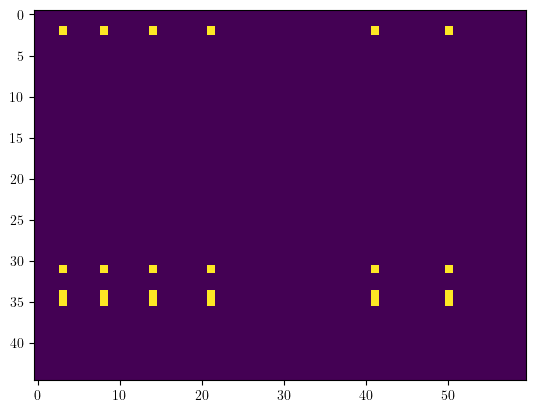

0 1


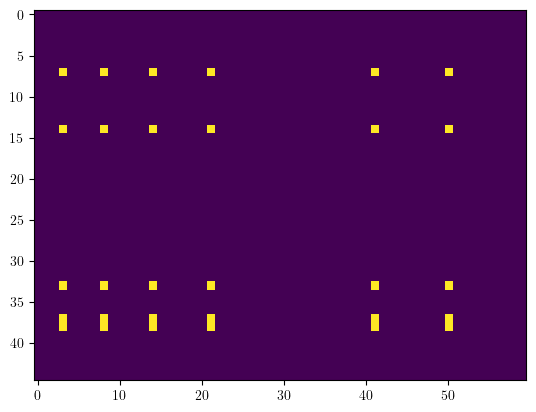

0 2


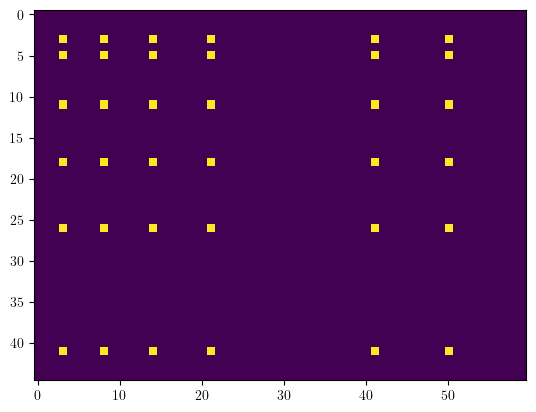

0 3


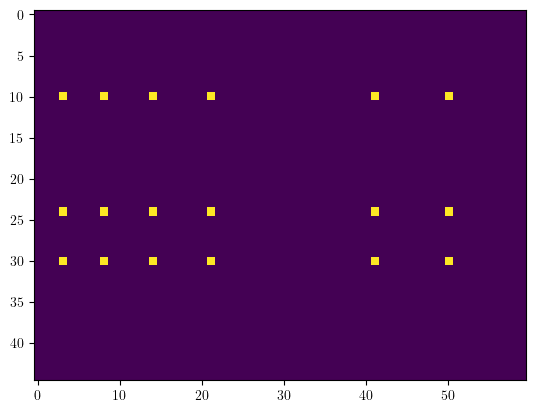

0 4


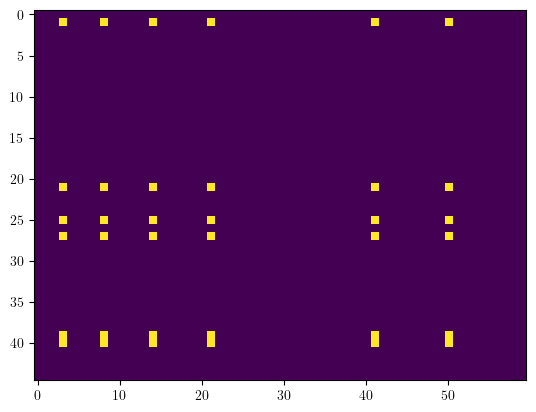

0 5


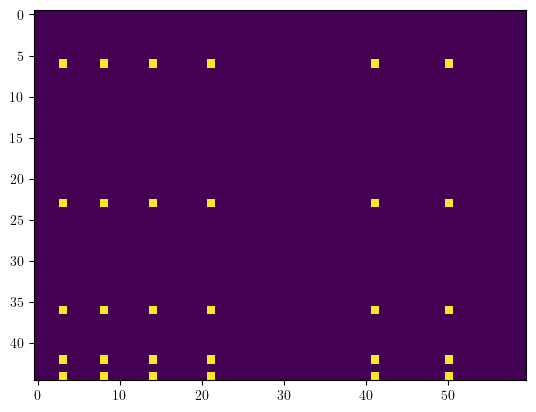

0 6


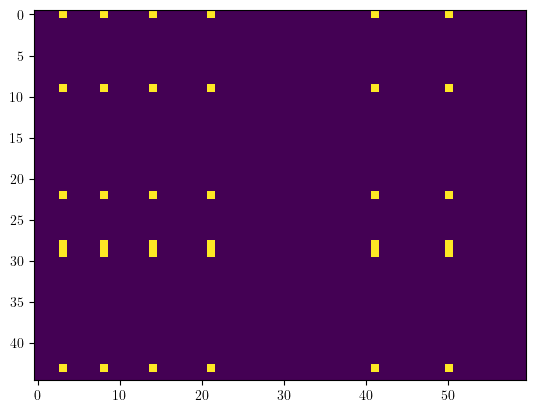

0 7


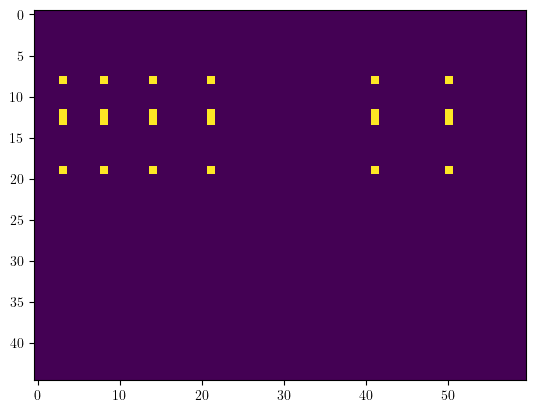

0 8


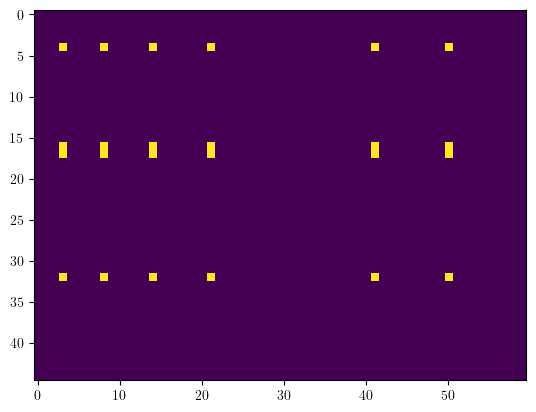

0 9


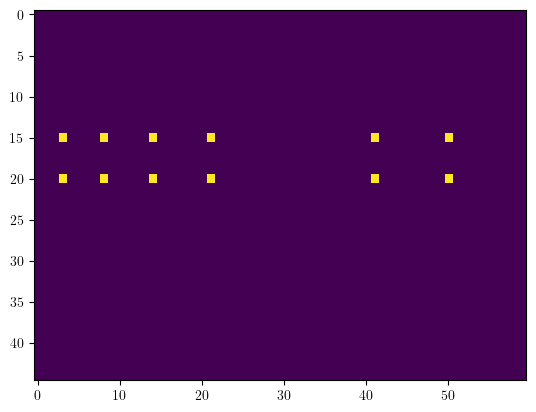

1 0


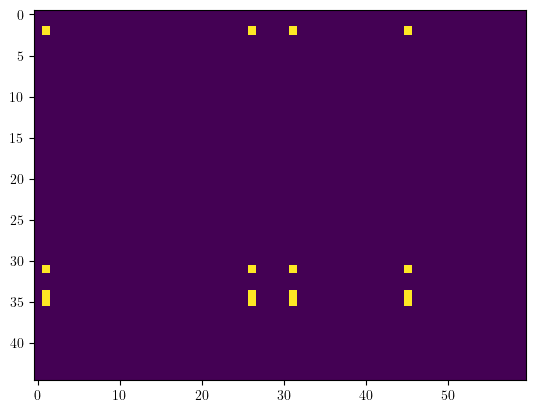

1 1


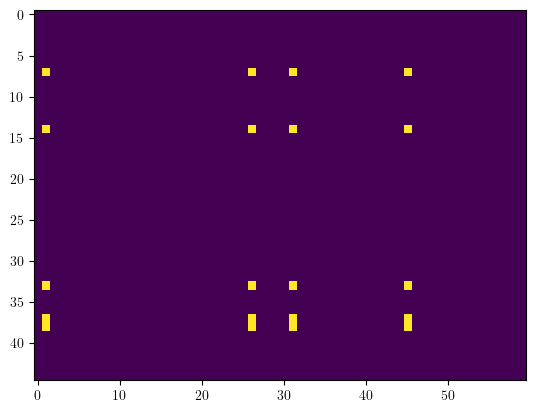

1 2


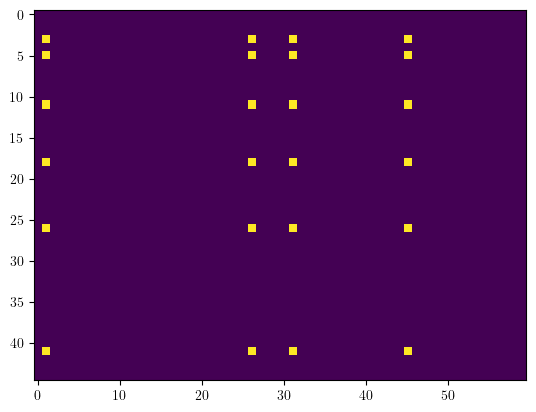

1 3


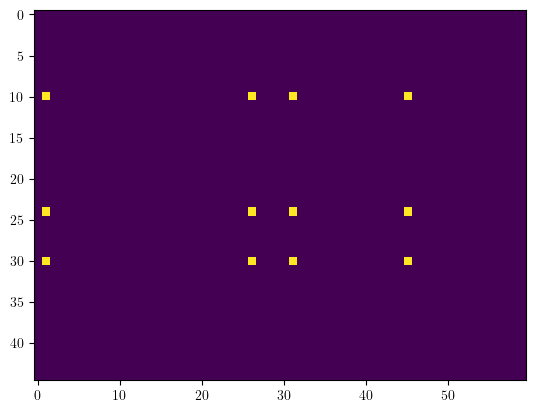

1 4


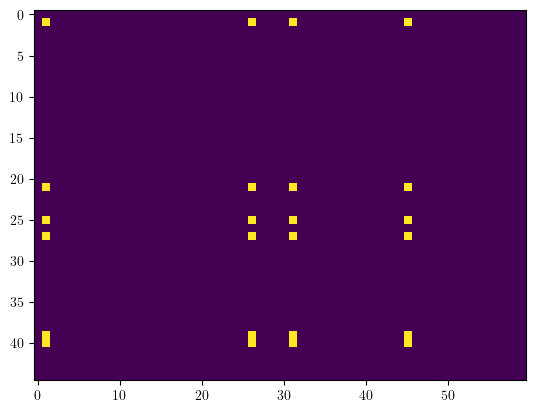

1 5


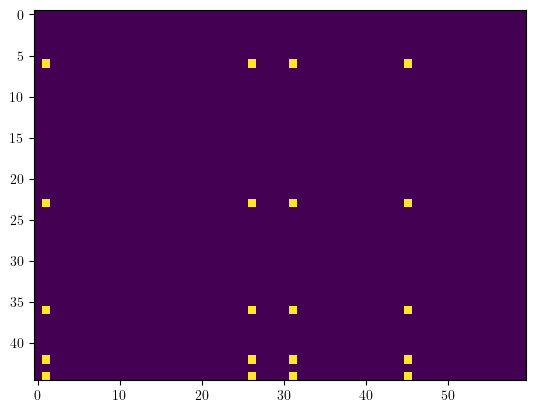

1 6


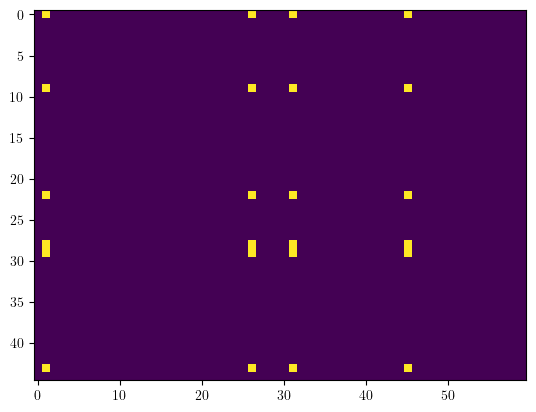

1 7


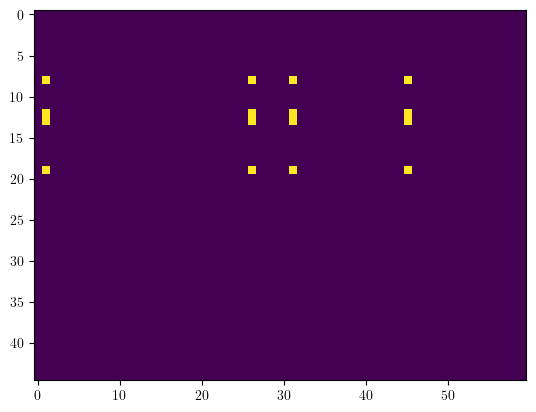

1 8


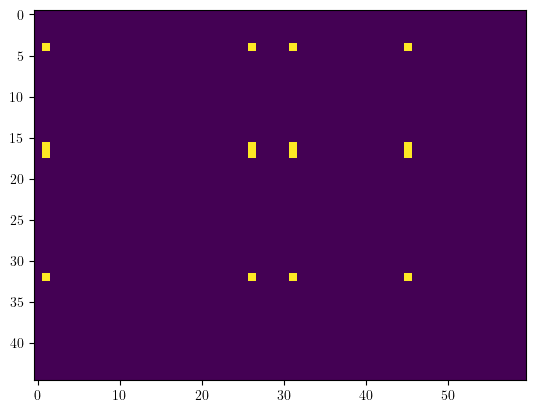

1 9


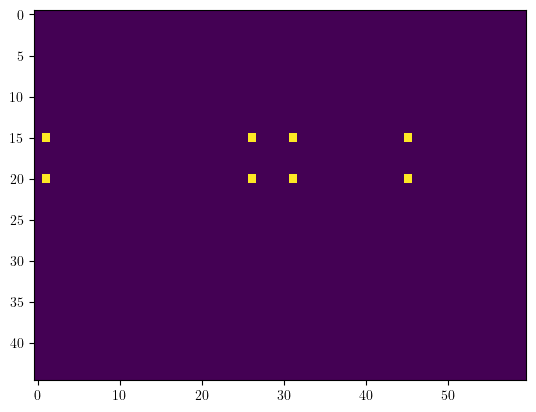

2 0


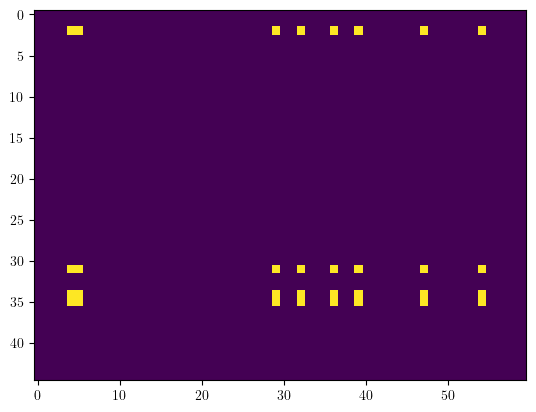

2 1


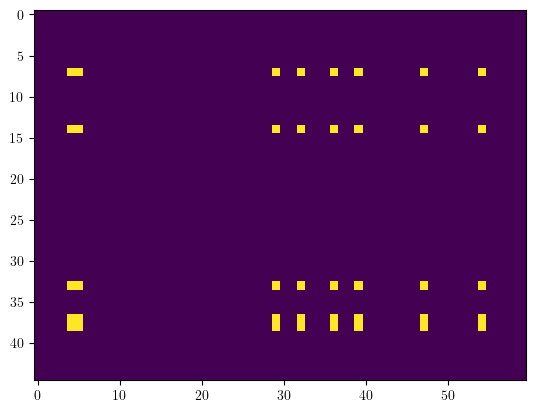

2 2


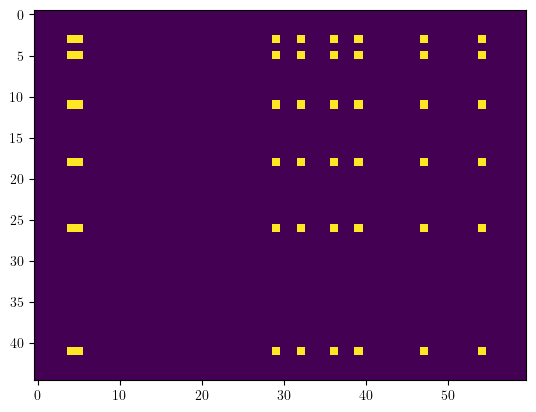

2 3


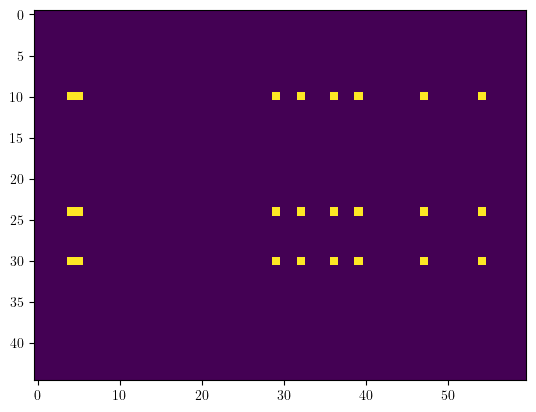

2 4


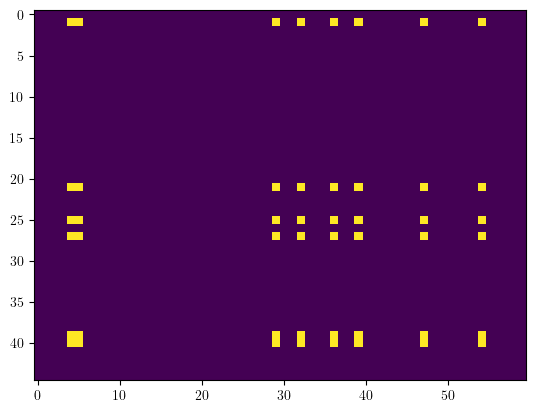

2 5


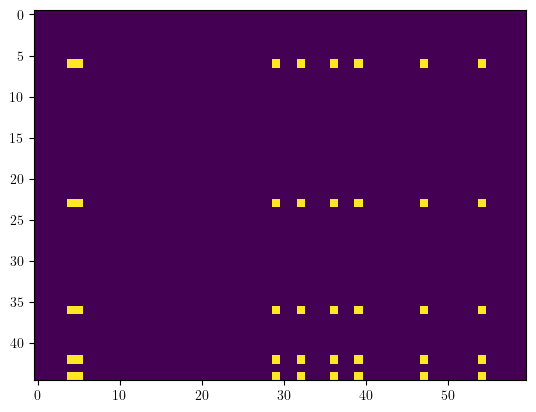

2 6


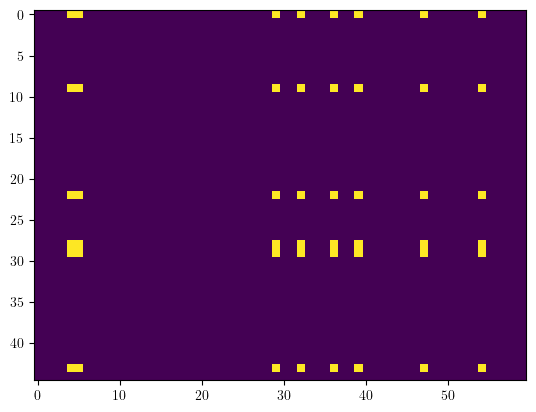

2 7


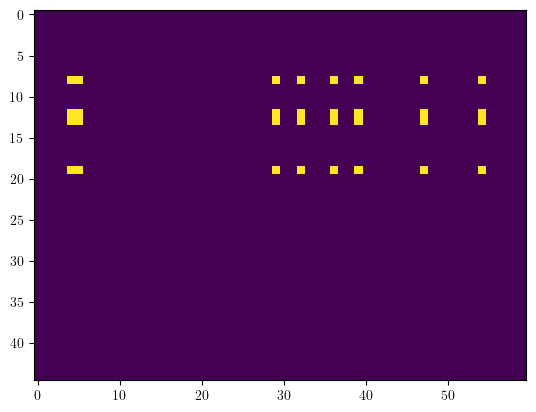

2 8


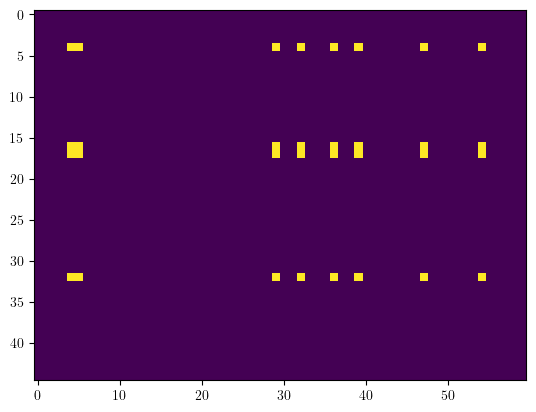

2 9


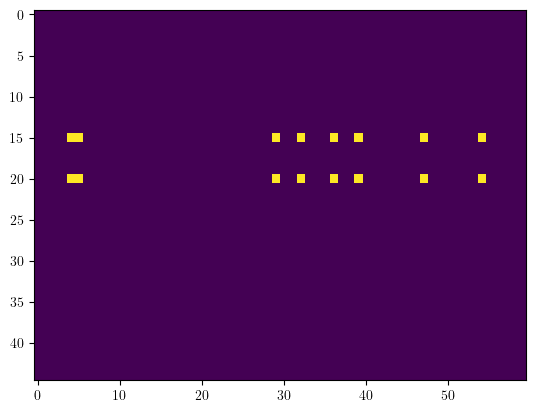

3 0


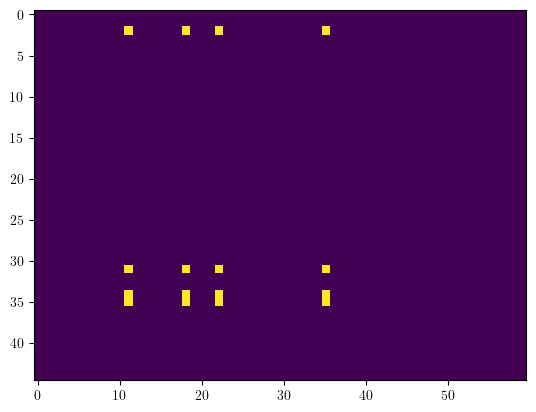

3 1


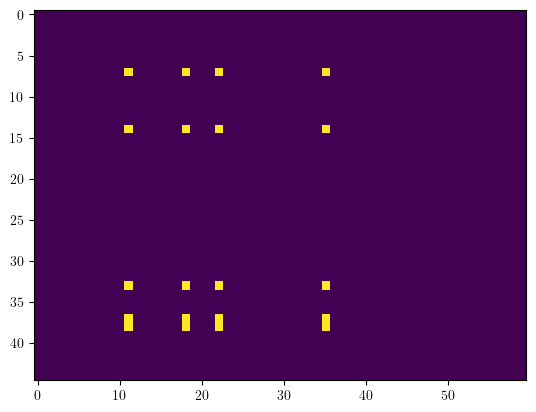

3 2


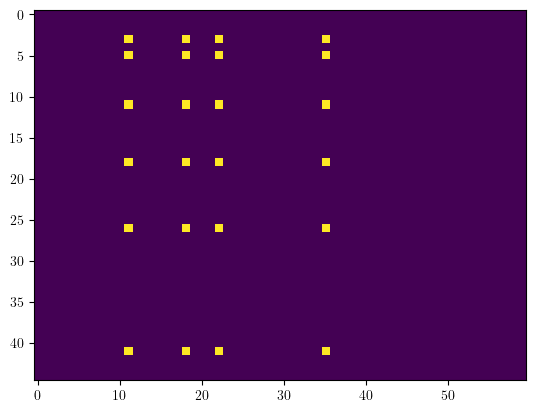

3 3


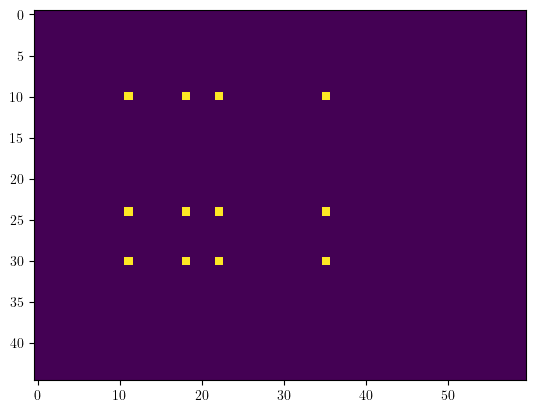

3 4


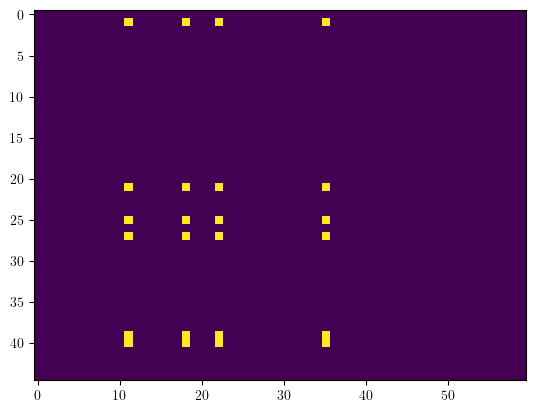

3 5


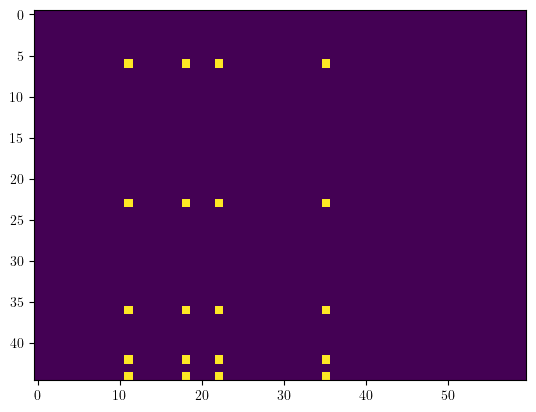

3 6


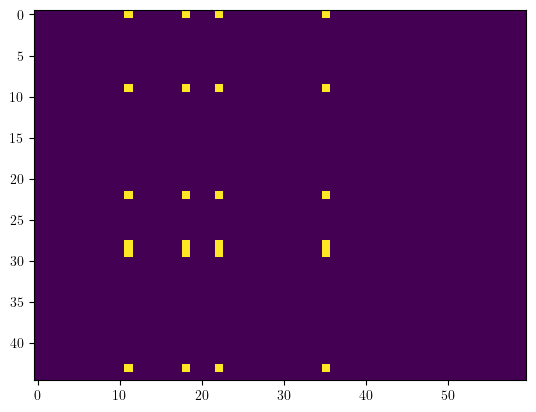

3 7


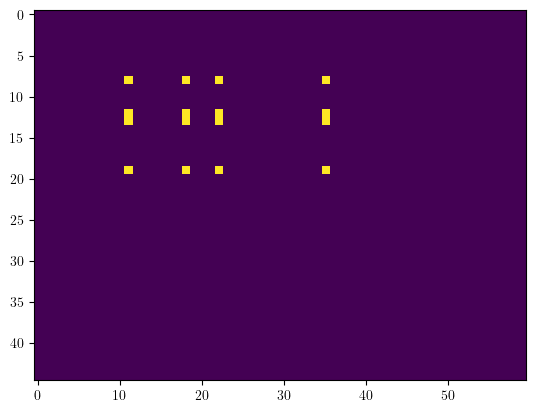

3 8


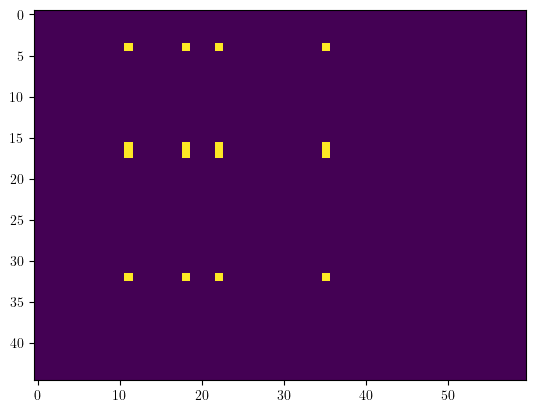

3 9


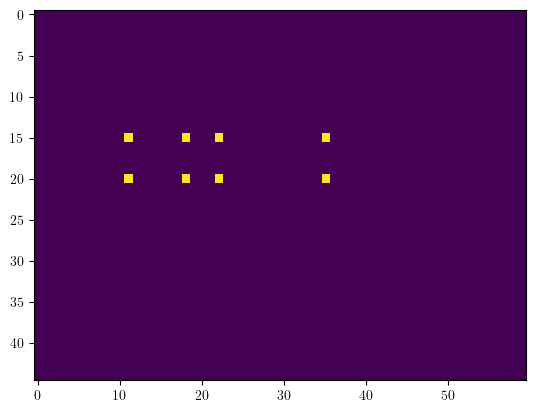

4 0


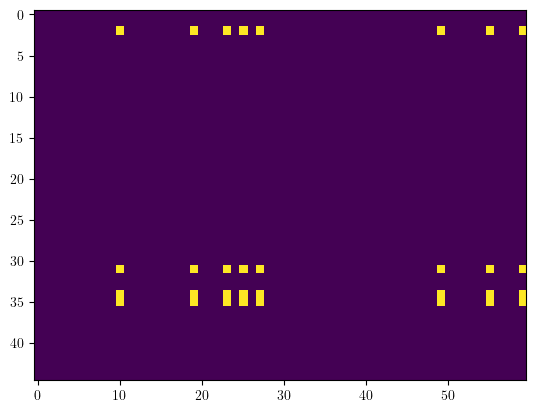

4 1


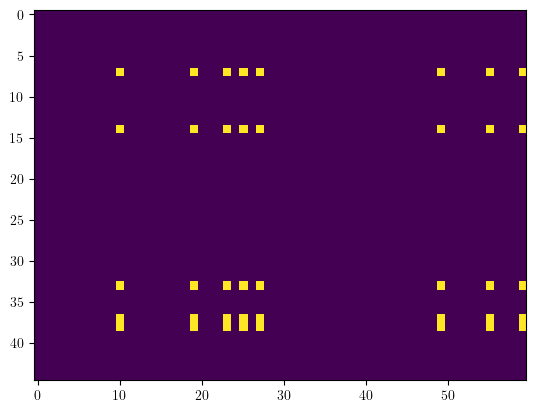

4 2


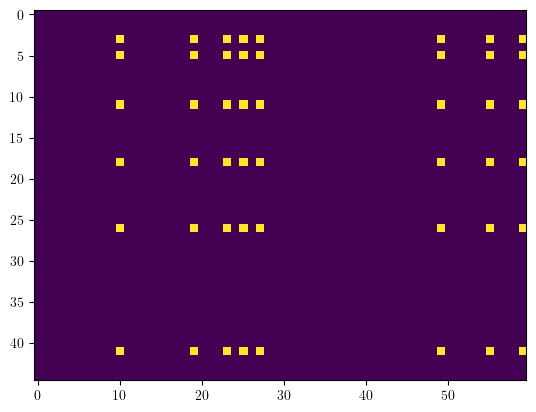

4 3


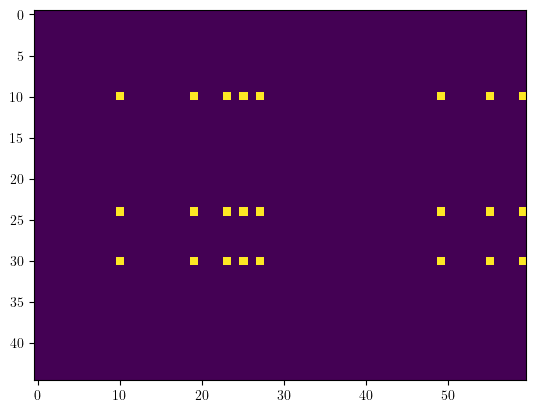

4 4


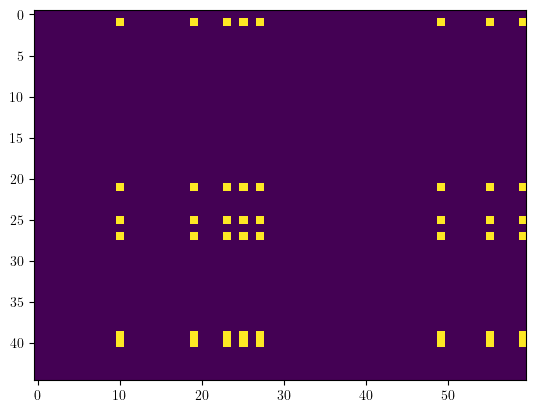

4 5


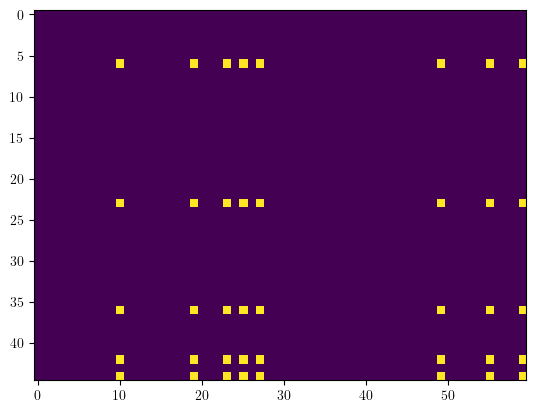

4 6


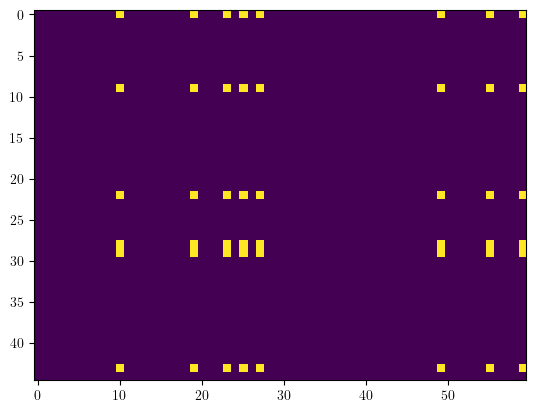

4 7


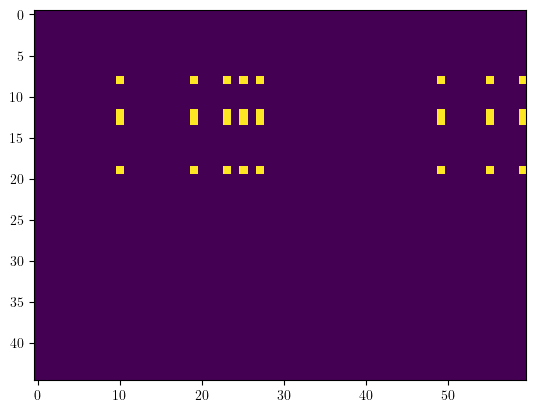

4 8


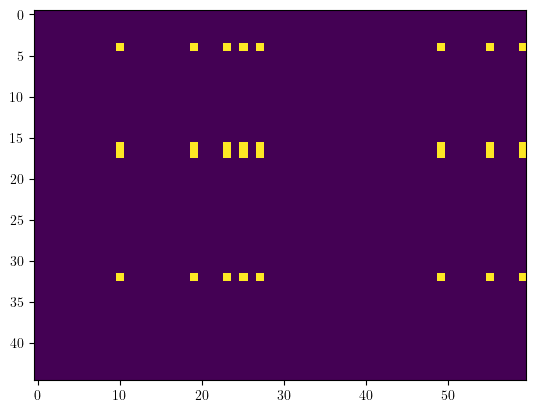

4 9


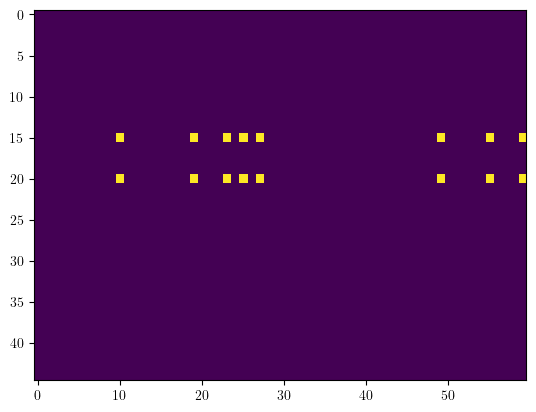

5 0


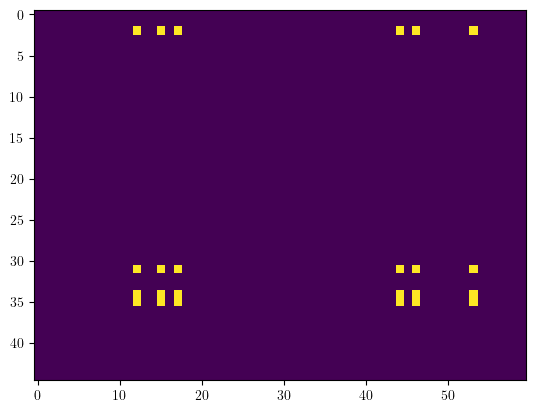

5 1


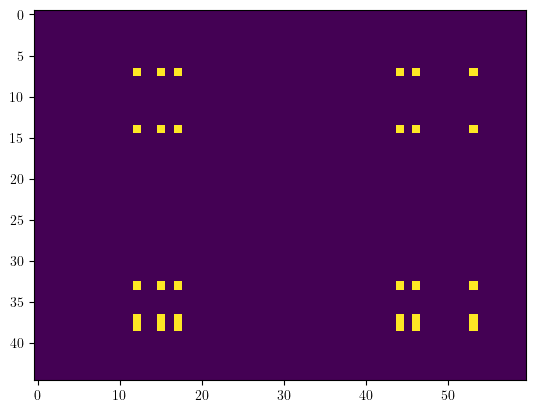

5 2


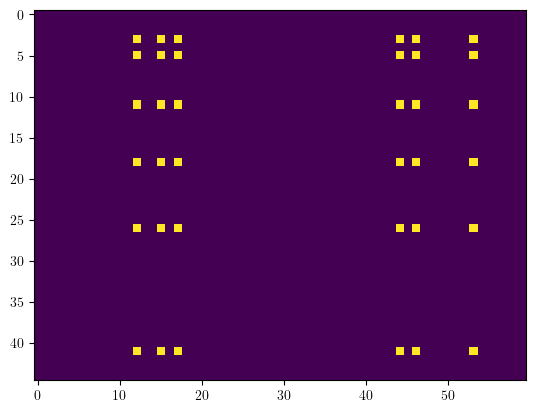

5 3


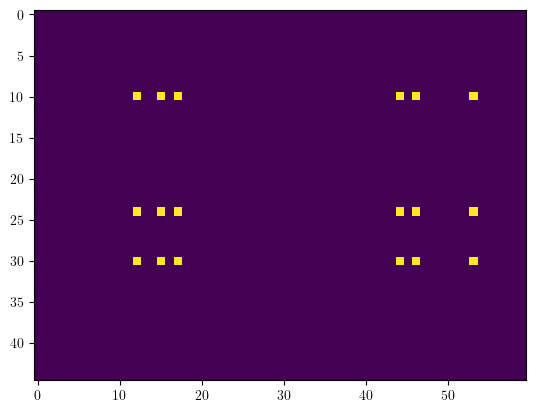

5 4


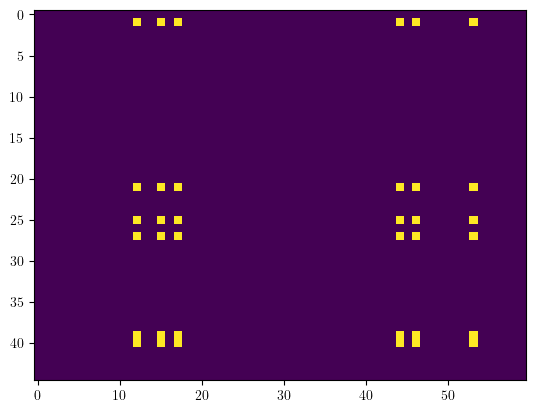

5 5


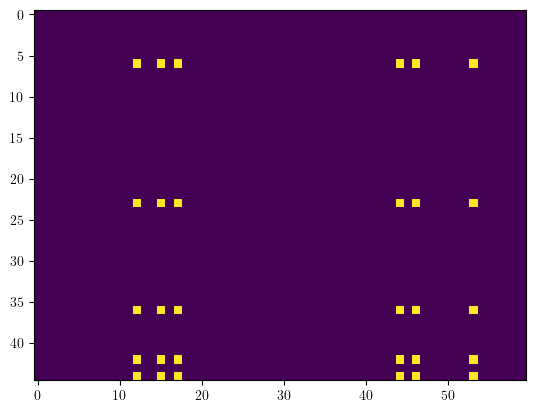

5 6


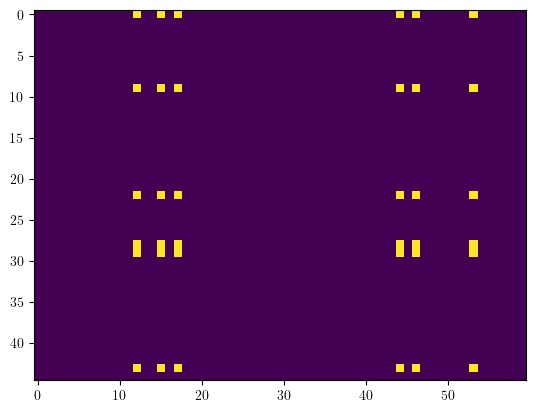

5 7


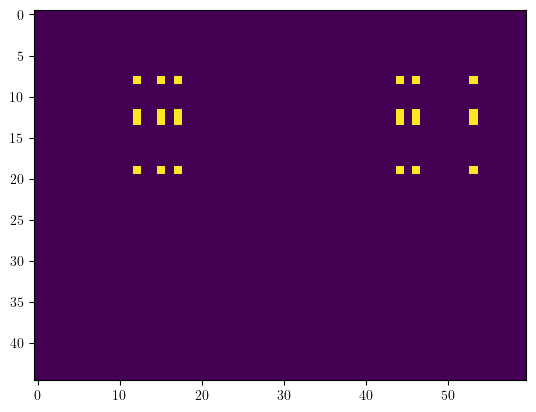

5 8


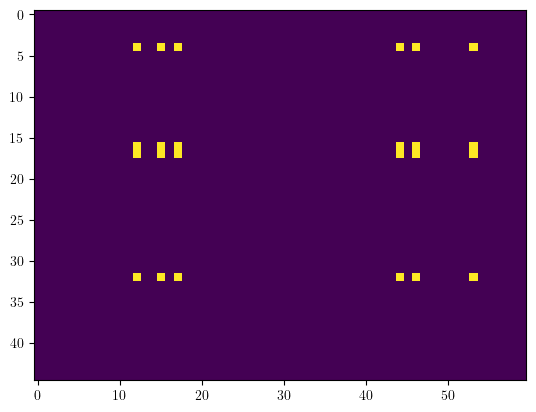

5 9


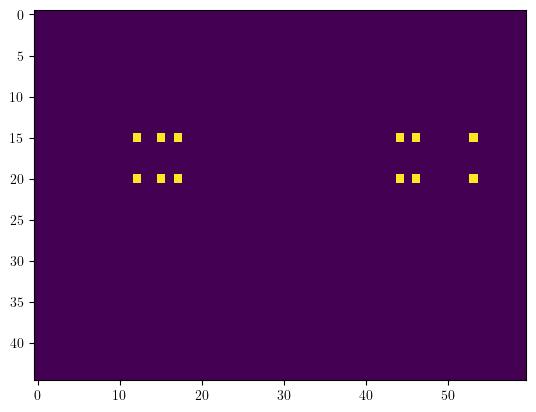

6 0


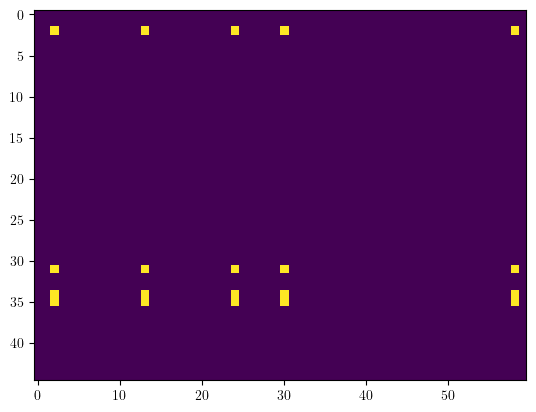

6 1


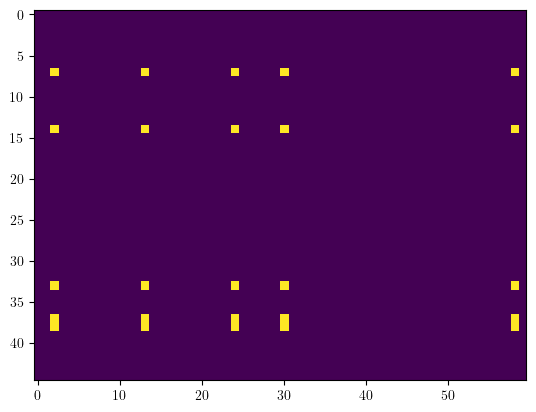

6 2


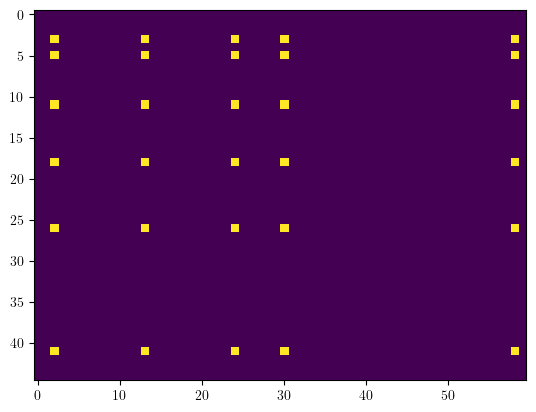

6 3


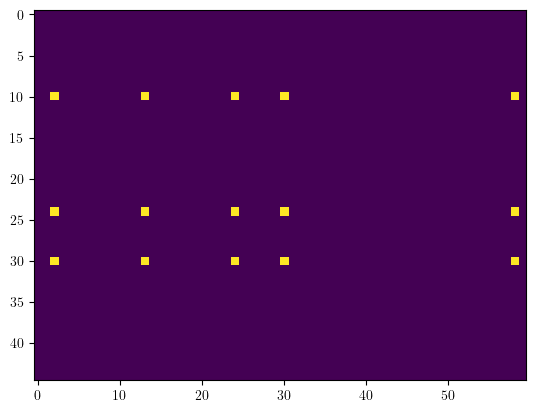

6 4


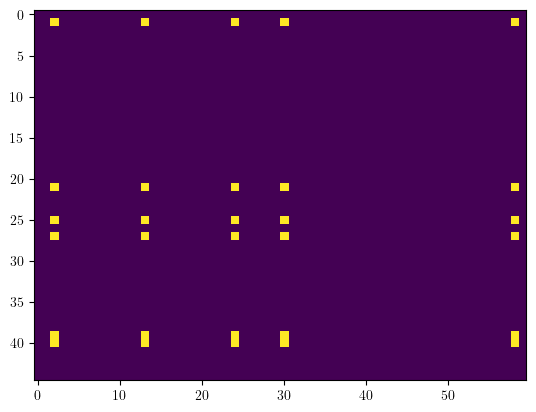

6 5


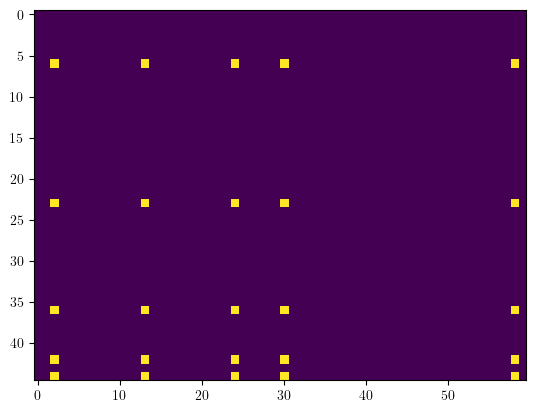

6 6


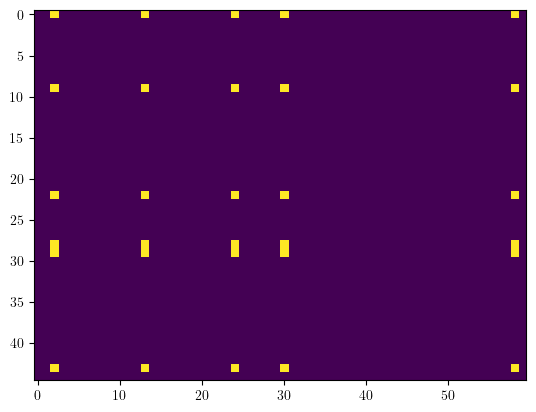

6 7


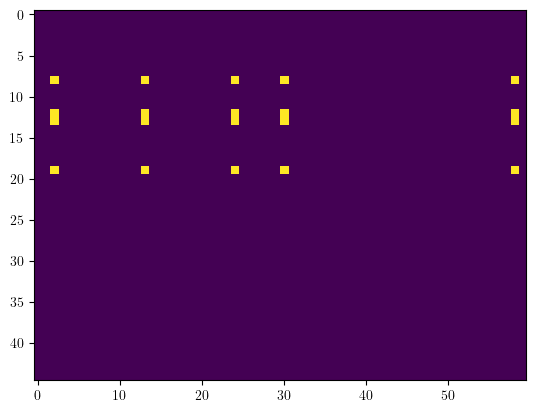

6 8


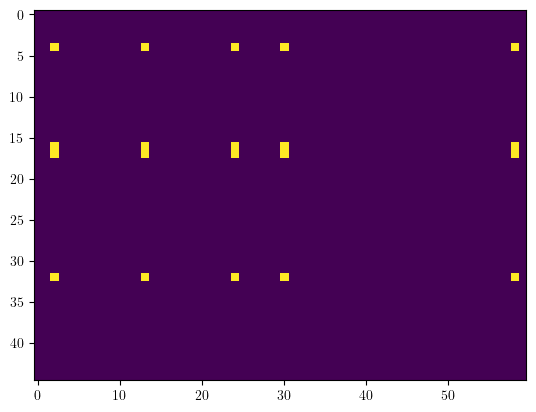

6 9


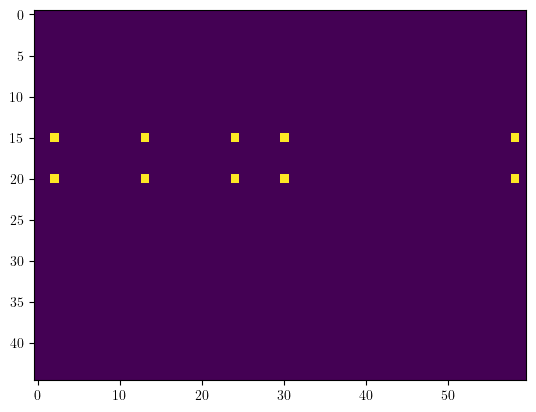

7 0


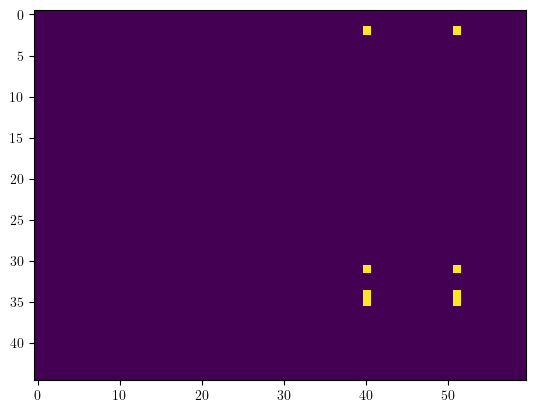

7 1


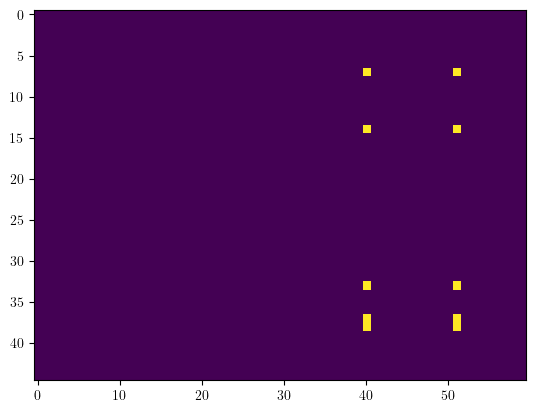

7 2


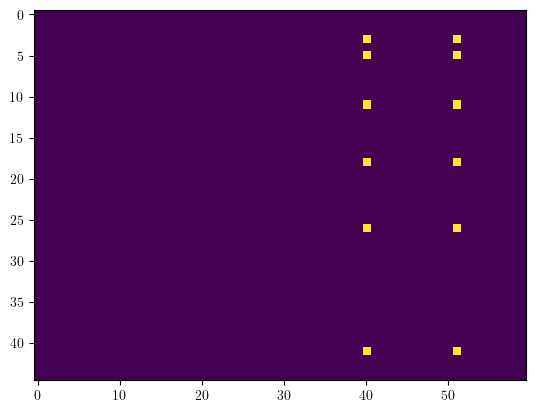

7 3


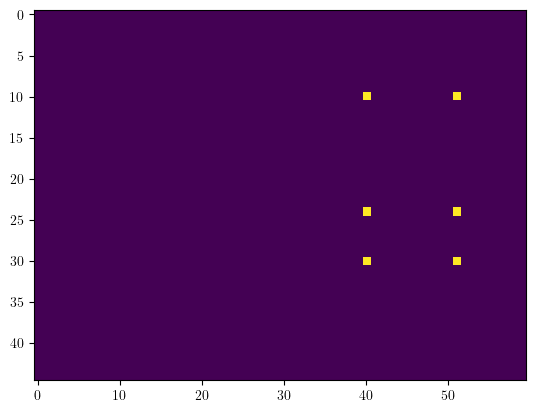

7 4


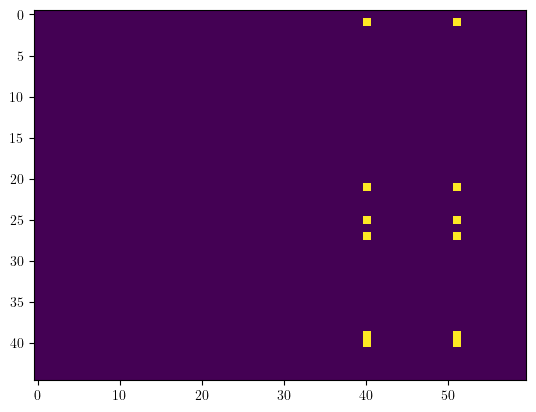

7 5


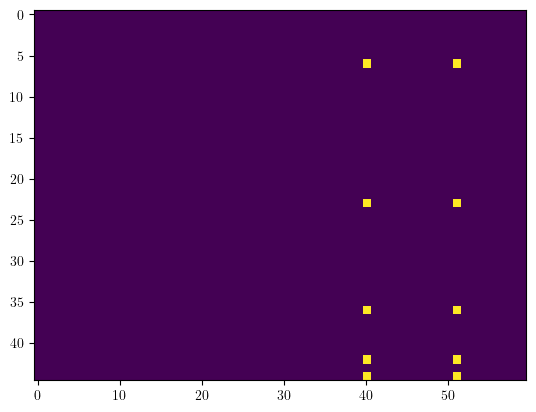

7 6


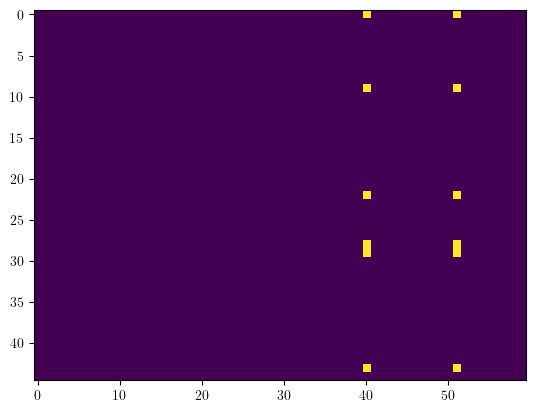

7 7


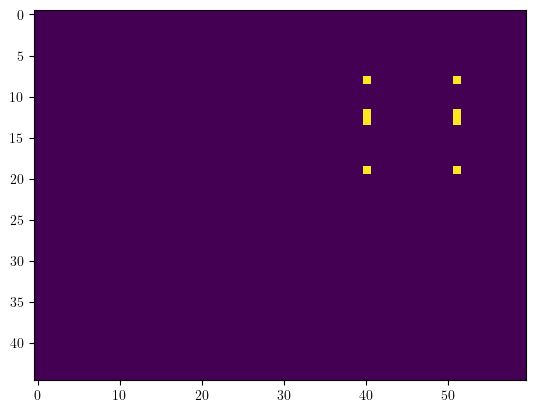

7 8


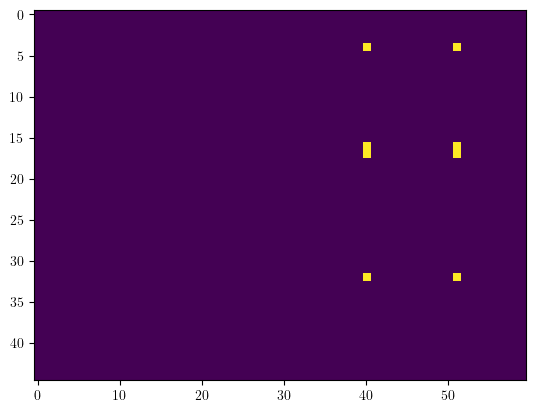

7 9


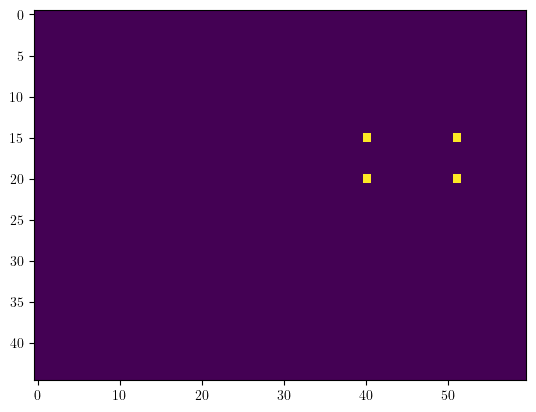

8 0


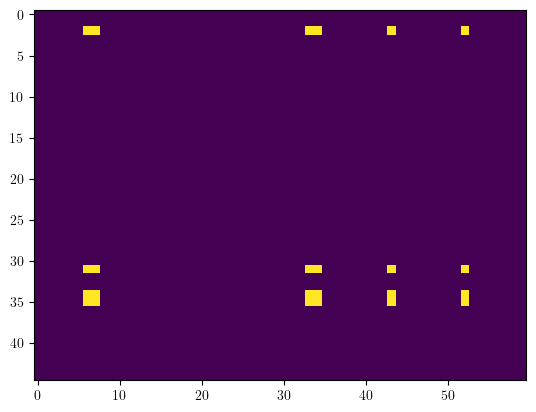

8 1


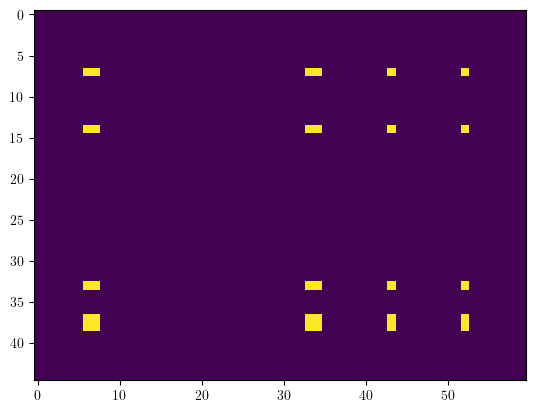

8 2


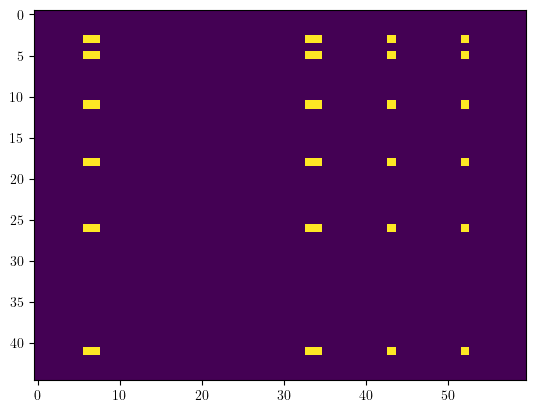

8 3


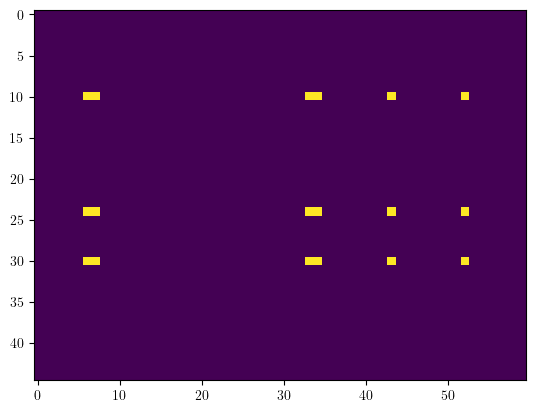

8 4


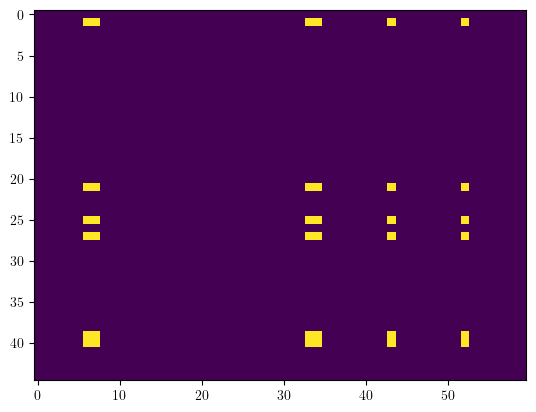

8 5


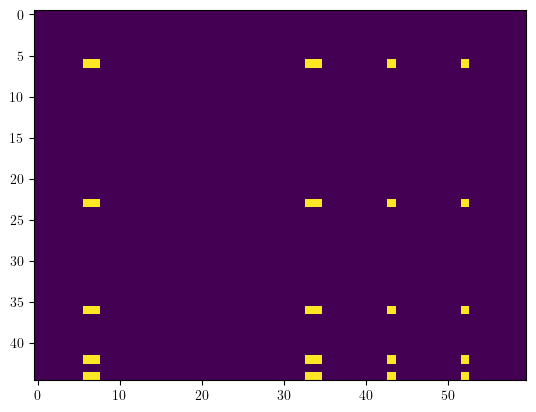

8 6


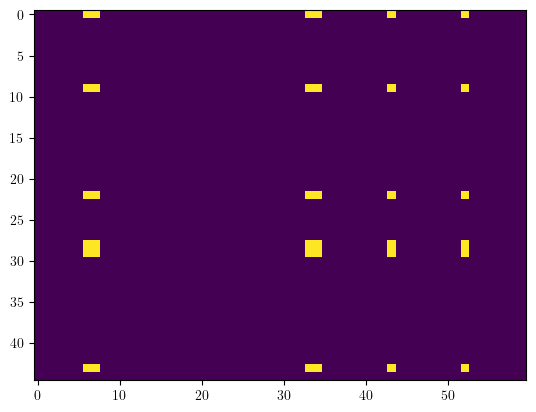

8 7


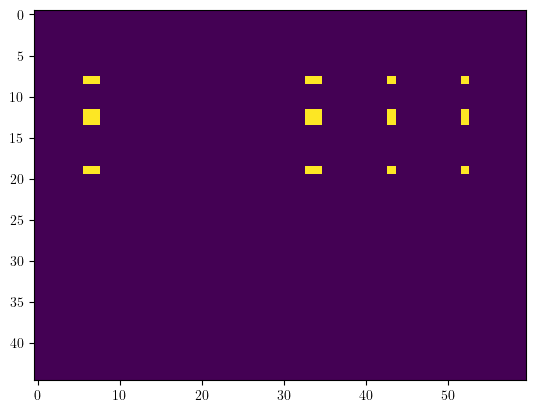

8 8


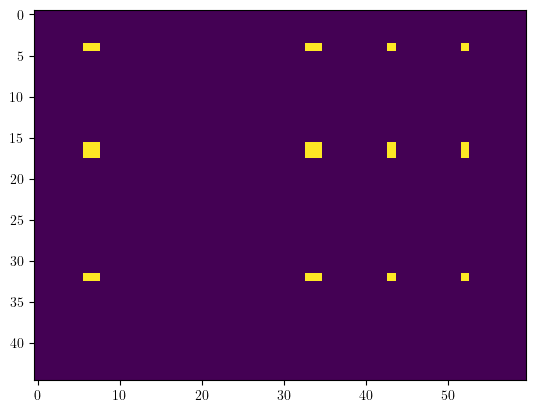

8 9


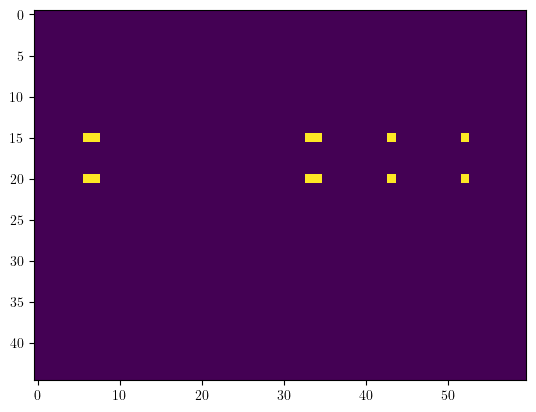

9 0


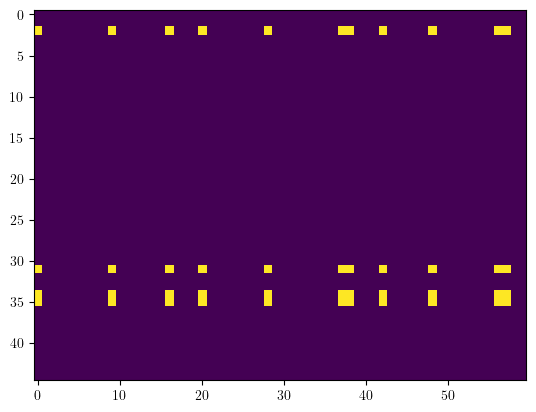

9 1


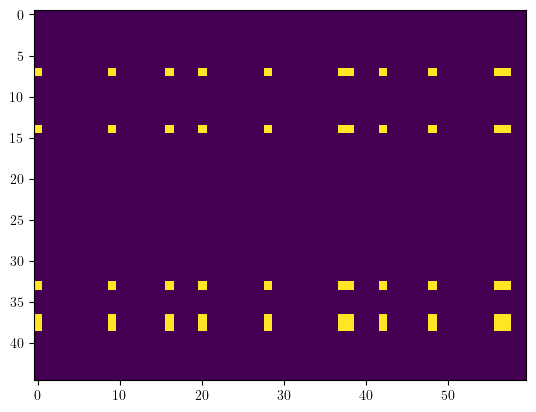

9 2


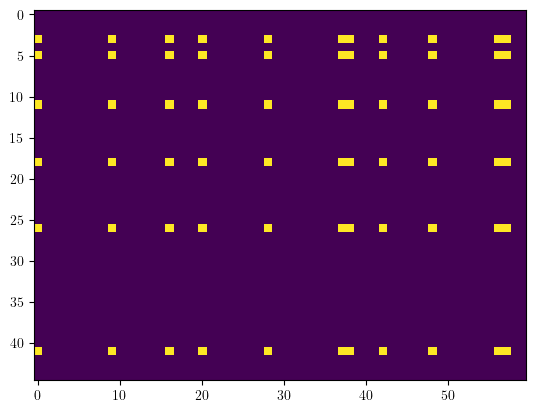

9 3


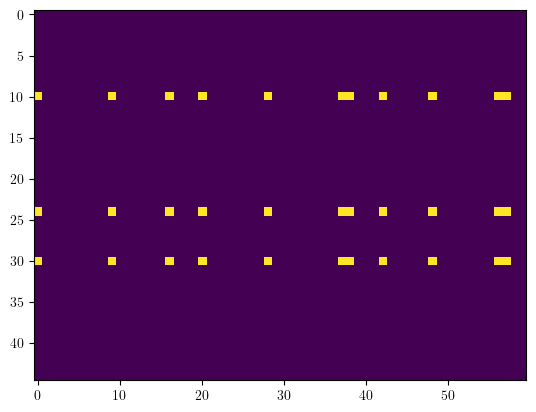

9 4


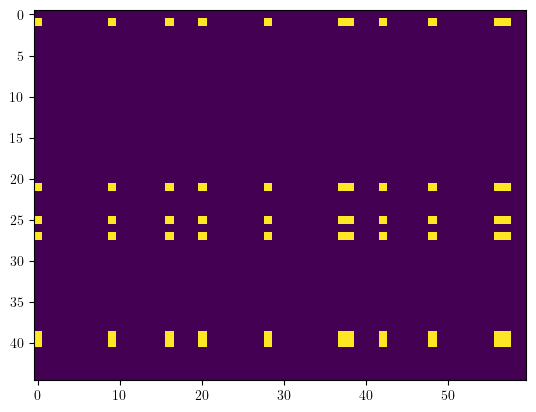

9 5


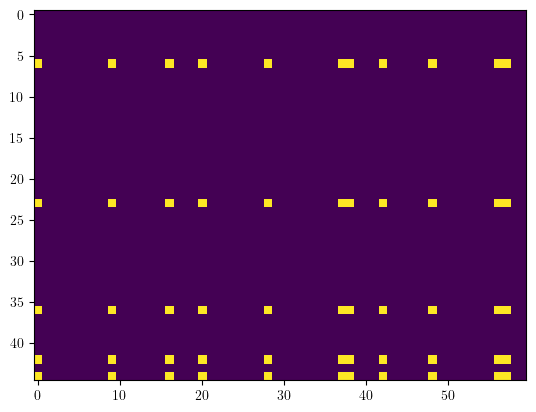

9 6


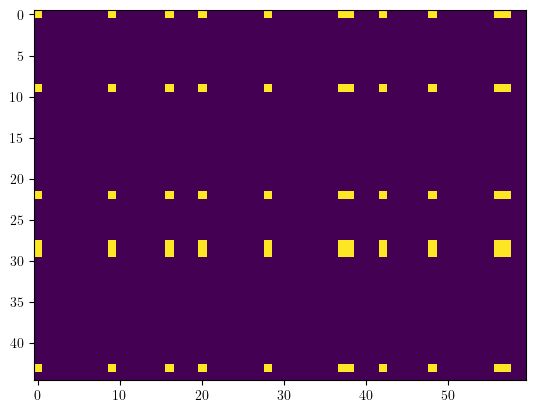

9 7


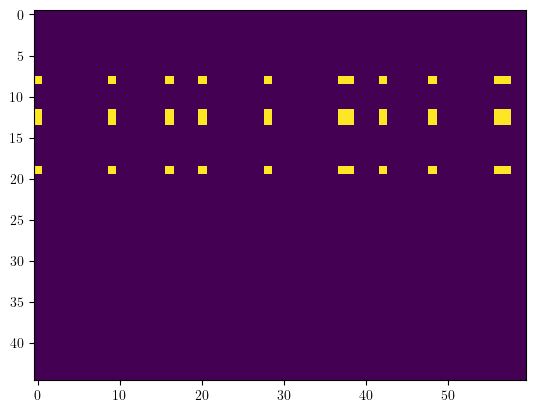

9 8


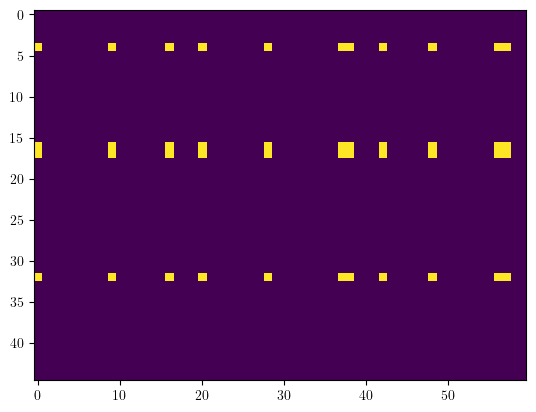

9 9


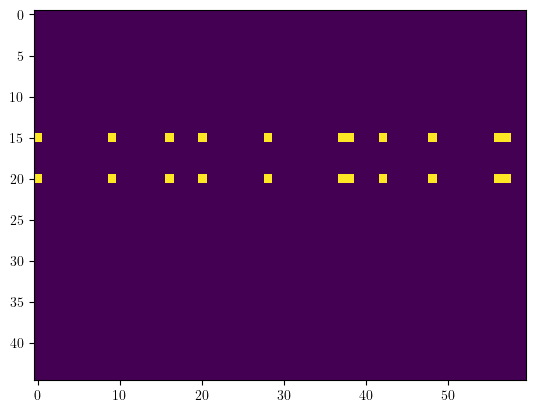

In [17]:
rvs,rvs_err,times, pltname,obs_times, rv_true, bc, period = est_rvs,reported_sigmas,np.tile(times,num_chunks).reshape(num_chunks,-1),'hogg_sim',times, true_epoch_rvs, bc_approx, star_period

import os
import scipy.sparse
rvs_total = rvs
rvs_error_total = rvs_err
rvs_clean = rvs_total - np.average(rvs_total[rvs_error_total > 0],weights=1/(rvs_error_total[rvs_error_total > 0])**2)
prediction_rvs = \
    irls_method_jack_knife(
        rvs_clean,
        rvs_error_total,
        times,
        Q=3, steps=20,
        lambda_offsets=1e-6, lambda_rvs=1e-6, n_sets = 10
    )

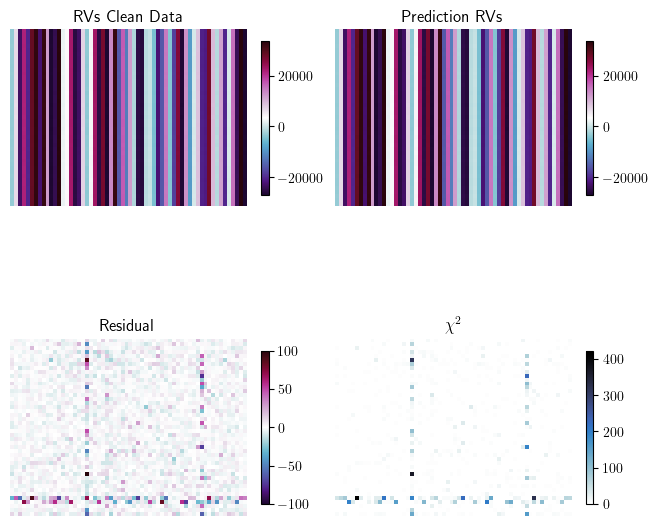

0.3827331261385141


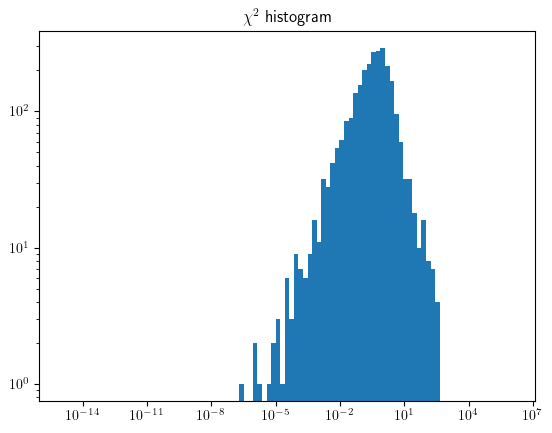

In [42]:
mappable = cmasher.viola
 # - bc_approx + bc_approx.mean()
fig,axes = plt.subplots(2,2,figsize=(8,8))
axes=axes.flatten()
im1 = axes[0].imshow(rvs_clean ,cmap=mappable)
im2 = axes[1].imshow(prediction_rvs,cmap=mappable)
im3 = axes[2].imshow(rvs_clean - prediction_rvs,cmap=mappable,vmin=-100,vmax=100)
im4 = axes[3].imshow(0.5/reported_sigmas**2 * (rvs_clean - prediction_rvs)**2,cmap=cmasher.arctic_r,vmin=0)
axes[0].axis('off')
axes[0].set_title('RVs Clean Data')
axes[1].axis('off')
axes[1].set_title('Prediction RVs')
axes[2].axis('off')
axes[2].set_title('Residual')
axes[3].axis('off')
axes[3].set_title('$\chi^2$')
plt.colorbar(im1,ax=axes[0],shrink=0.5)
plt.colorbar(im2,ax=axes[1],shrink=0.5)
plt.colorbar(im3,ax=axes[2],shrink=0.5)
plt.colorbar(im4,ax=axes[3],shrink=0.5)
plt.subplots_adjust(hspace=0.01,wspace=0.1)
# plt.savefig(os.path.join(out_dir,'sim_data_summary.png'),dpi=200,bbox_inches='tight')
plt.show()

plt.title('$\chi^2$ histogram')
print(np.median((0.5/reported_sigmas**2 * (rvs_clean - prediction_rvs)**2).flatten()))
bins = np.logspace(np.log((0.5/reported_sigmas**2 * (rvs_clean - prediction_rvs)**2).min()),np.log((0.5/reported_sigmas**2 * (rvs_clean - prediction_rvs)**2).max()),100)
plt.hist((0.5/reported_sigmas**2 * (rvs_clean - prediction_rvs)**2).flatten(),bins=bins)
plt.yscale('log')
plt.xscale('log')
plt.show()

In [29]:
# ------------------------------------------------------------------ #
#  Wrapper that calls the above inside analyze_comb                   #
# ------------------------------------------------------------------ #
def analyze_comb(rvs,rvs_err,times, pltname,
                 obs_times, rv_true, bc, period, out_dir,
                 options):
    """
    rvs1_grp  : HDF5 group with keys RVs, RV_err_c, RV_err_e, Times
    pltname   : string suffix for the saved file
    all_loss  : passed through (unused in plot, kept for compatibility)
    obs_times : astropy Time array for true RV times
    rv        : true RV array (astropy Quantity, m/s)
    target    : astropy SkyCoord
    location  : astropy EarthLocation
    out_dir   : output directory path
    reiterative_reweighting_method : your solver function
    """
    import os
    rvs_total = rvs
    rvs_error_total = rvs_err
    rvs_clean = rvs_total - np.average(rvs_total[rvs_error_total > 0],weights=1/(rvs_error_total[rvs_error_total > 0])**2)
    rvs_comb, offsets, rvs_comb_info, offsets_info, reweight = \
        jabble.quickplay.irls_method(
            rvs_clean,
            rvs_error_total,
            times,
            Q=3, steps=20,
            lambda_offsets=1e-6, lambda_rvs=1e-6,
        )

    fig, axes = plt.subplots(
        1, 3,
        figsize=(10, 4),
        constrained_layout=True,

    )
    bins = 10**(np.linspace(-1,3))

    axes[0].set_title('Reweight Factors')
    axes[0].hist(1/np.sqrt(reweight[reweight != 0].flatten()),bins=bins)
    axes[0].set_xscale('log')

    # bins = 10**(np.linspace(-1,4))
    axes[1].set_title('Error on Raw RV')
    axes[1].hist(rvs_error_total.flatten(),bins=bins)
    axes[1].set_xscale('log')

    # bins = 10**(np.linspace(-1,4))
    axes[2].set_title('Reweighted Error')
    axes[2].hist(1.0 / np.sqrt(reweight).flatten() * rvs_error_total.flatten(),bins=bins)
    axes[2].set_xscale('log')
    plt.savefig(
        os.path.join(out_dir, f'rv_err_{pltname}.png'),
        dpi=150, bbox_inches='tight',
    )
    plt.show()
    
    fig, axes = plt.subplots(
        2, 3,
        figsize=(10, 8),
        height_ratios=[1, 1],
        constrained_layout=True,
    )
    fig.suptitle(f'RV Model Comparison — {pltname}', fontsize=12)

    plt_bcs = bc - bc.mean() + rvs_comb.mean()
    
    mask_rvs = np.isnan(rvs_total) | np.isinf(rvs_total) | np.isnan(rvs_error_total) | np.isinf(rvs_error_total) 
    mask_comb = np.isnan(rvs_comb) | np.isinf(rvs_comb) | np.isnan(1.0 / np.sqrt(rvs_comb_info)) | np.isinf(1.0 / np.sqrt(rvs_comb_info)) 
    mask_true = np.isnan(rv_true) | np.isinf(rv_true)
    mask_col = np.any(mask_rvs,axis=0) | mask_comb | mask_true
    
    plt_rvs = rvs_clean
    plt_rvs_comb = rvs_comb #- rvs_comb.mean()
    plt_rv_true = rv_true - rv_true.mean() + rvs_comb.mean()#np.average(np.array(rvs1_grp['RVs'][rvs1_grp['RV_err_c'][:] > 0]),weights=1/(rvs1_grp['RV_err_c'][rvs1_grp['RV_err_c'][:] > 0])**2)*u.m/u.s
    
    axes[0,:] = plot_rv_model_compare(
        axes[0,:][None,:],
        time1       = times,
        rv_est      = plt_rvs,
        rv_est_err  = rvs_error_total,
        time_comb   = times[0, :],
        rv_est_comb = plt_rvs_comb,
        rv_err_comb = 1.0 / np.sqrt(rvs_comb_info),
        time2       = obs_times,
        rv_true     = plt_rv_true,
        period      = period,
        offset_param= offsets,
        reweight_err= 1.0 / np.sqrt(reweight) * rvs_error_total,
        bc          = plt_bcs,
        options = options
    )


    # plt.savefig(
    #     os.path.join(out_dir, f'rv_comb_{pltname}.png'),
    #     dpi=150, bbox_inches='tight',
    # )
    # plt.show()


    # Plot Data wrt chunks to show offset fits
    # fig, axes = plt.subplots(
    #     1, 3,
    #     figsize=(10, 4),
    #     height_ratios=[1],
    #     constrained_layout=True,
    # )
    # fig.suptitle(f'Offset Model Comparison — {pltname}', fontsize=12)

    axes[1,:] = plot_offset_model_compare(
        axes[1,:][None,:],
        time1       = times,
        rv_est      = plt_rvs,
        rv_est_err  = rvs_error_total,
        time_comb   = times[0, :],
        rv_est_comb = plt_rvs_comb,
        rv_err_comb = 1.0 / np.sqrt(rvs_comb_info),
        time2       = obs_times,
        rv_true     = plt_rv_true,
        period      = period,
        offset_param= offsets,
        offset_param_err = 1/np.sqrt(offsets_info),
        reweight_err= 1.0 / np.sqrt(reweight) * rvs_error_total,
        bc          = plt_bcs,
        options=options
    )

    fig.savefig(

        os.path.join(out_dir, f'offest_comb_{pltname}.png'),
        dpi=150, bbox_inches='tight',
    )
    plt.show()

    # Histogram of Residuals over error
    for i in range(rvs_clean.shape[0]):
        plt.errorbar(np.arange(0,rvs_clean.shape[1]),(rvs_clean[i,:] - rvs_comb[:] - offsets[i]),\
                     yerr=rvs_error_total[i,:]/np.sqrt(reweight[i,:]),fmt='.')

    plt.show()

    # for i in range(rvs_clean.shape[0]):
    fig, axes = plt.subplots(
        1,1,
        figsize=(4, 4),
        height_ratios=[1],
        constrained_layout=True,
    )
    plt.hist(((rvs_clean - rvs_comb[None,:] - offsets[:,None])*np.sqrt(reweight)/rvs_error_total).flatten(),bins=100)
    # plt.title('Residual RV / Sigma RV: sigma: {}'.format(np.std(((rvs_clean - rvs_comb[None,:] - offsets[:,None])*np.sqrt(reweight)/rvs_error_total).flatten())))
    plt.xlabel('$\chi^2$')
    plt.ylabel('Counts')
    fig.savefig(
        os.path.join(out_dir, f'model_chi_{pltname}.png'),
        dpi=150, bbox_inches='tight',
    )
    print(np.std(((rvs_clean - rvs_comb[None,:] - offsets[:,None])*np.sqrt(reweight)/rvs_error_total)))
    plt.show()

    return rvs_comb, offsets, rvs_comb_info, offsets_info, reweight

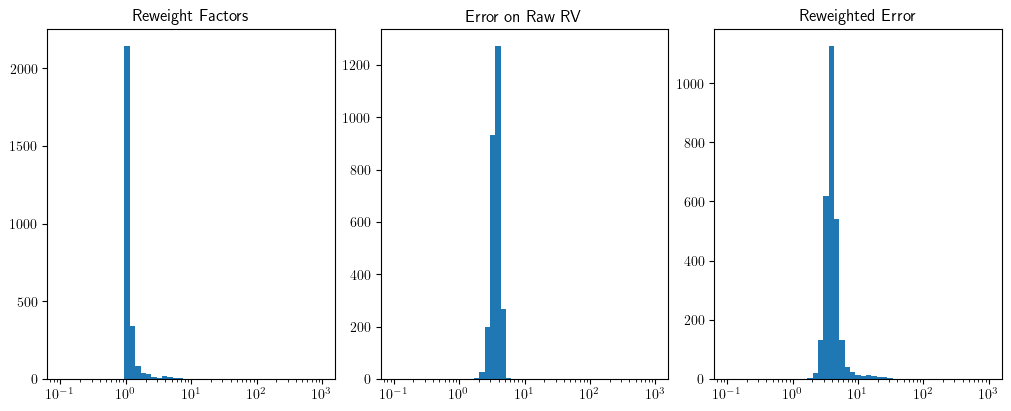

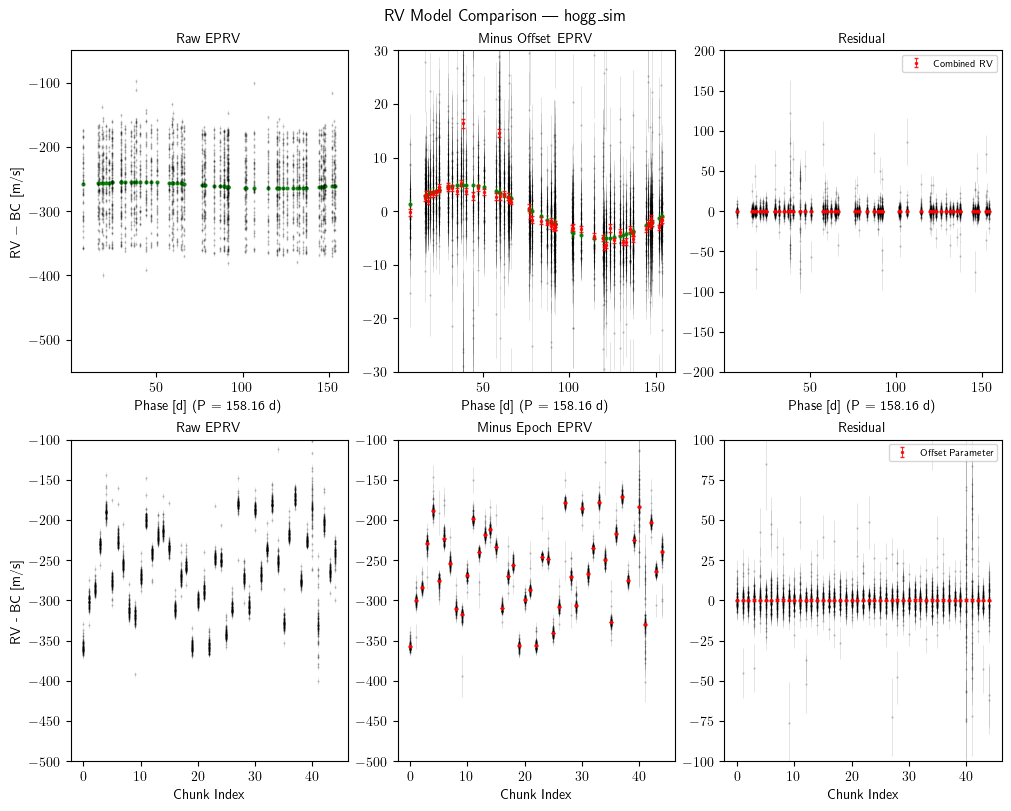

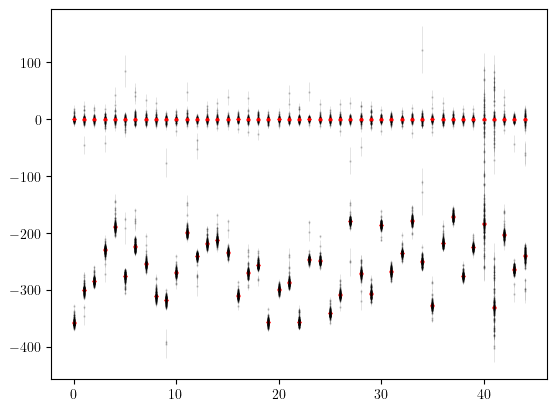

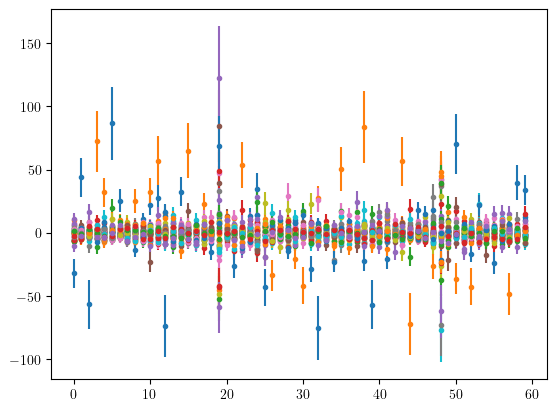

1.1730720977760576


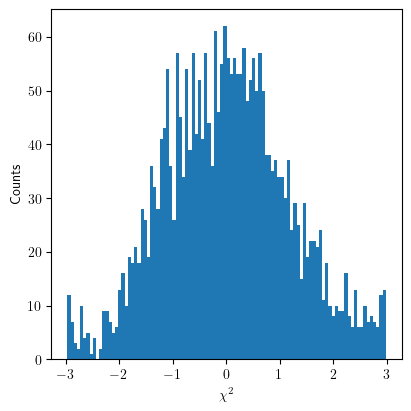

In [34]:
options={
    'offset_col1_yrange' : 2e2,
    'offset_col1_mid' : -3e2,
    'offset_col2_yrange' : 2e2,
    'offset_col2_mid' : -3e2,
    'offset_col3_yrange' : 1e2,
    'rv_eprv_yrange1' : 2.5e2,
    'rv_eprv_yrange2' : 3e1,
    'rv_eprv_mid1' : -3e2,
    'rv_eprv_mid2' : 0,
    # 'rv_rv_yrange' : 4e4,
    'rv_res_yrange' : 2e2
}
rvs_comb, offsets, rvs_comb_info, offsets_info, reweight = analyze_comb(est_rvs,reported_sigmas,\
                                                                        np.tile(times,num_chunks).reshape(num_chunks,-1),\
                                                                        'hogg_sim',times, true_epoch_rvs, bc_approx, \
                                                                        star_period, out_dir,options=options)

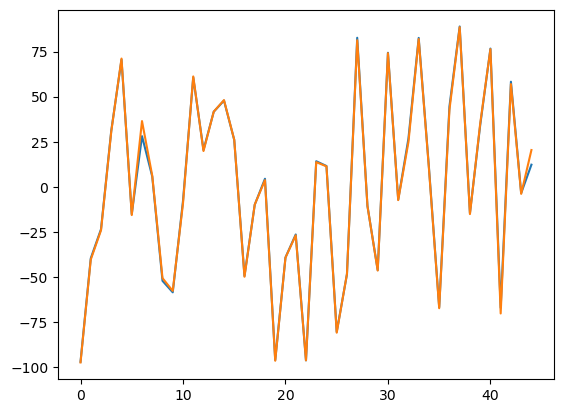

In [19]:
plt.plot(chunk_offsets-np.mean(chunk_offsets))
plt.plot(offsets- np.mean(offsets))
plt.show()

In [20]:
np.mean(1/np.sqrt(rvs_comb_info)),np.mean(reported_sigmas)/np.sqrt(num_epochs),np.mean(reported_sigmas)

(0.5812246410270275, 0.4713283846456448, 3.650893968654852)

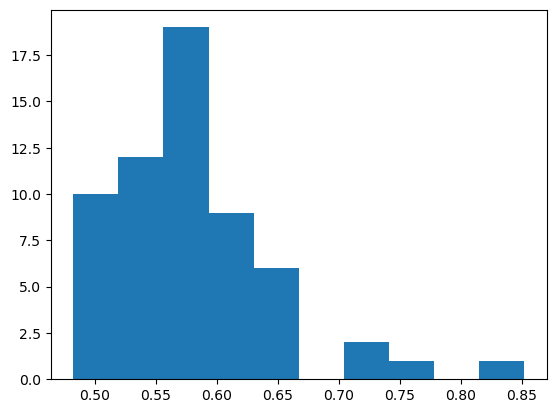

In [21]:
plt.hist(1/np.sqrt(rvs_comb_info))
plt.show()

In [22]:
# est_rvs[bad_both_ind[:,0],bad_both_ind[:,1]],bad_both_ind_2

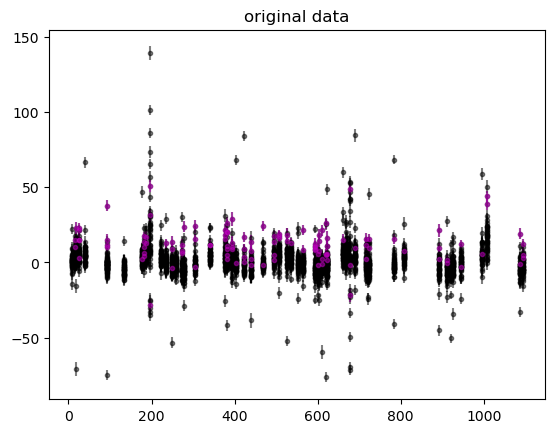

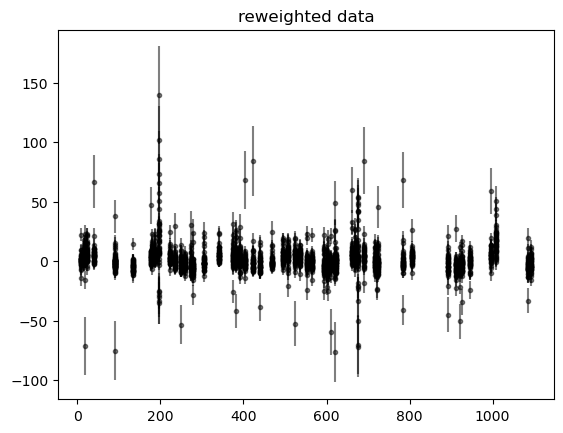

In [23]:
plt.title('original data')
for ii in range(est_rvs.shape[0]):
    plt.errorbar(times,est_rvs[ii,:]-bc_approx-chunk_offsets[ii],yerr=reported_sigmas[ii,:],fmt='k.',label='data',alpha=0.5)

# for ii in bad_chunk_ind:
#     plt.errorbar(times,est_rvs[ii,:]-bc_approx-chunk_offsets[ii],yerr=reported_sigmas[ii,:],fmt='r.',label='data',alpha=0.5)
# for ii in bad_chunk_ind_2:
#     plt.errorbar(times,est_rvs[ii,:]-bc_approx-chunk_offsets[ii],yerr=reported_sigmas[ii,:],fmt='b.',label='data',alpha=0.5)

# for ii in bad_epoch_ind:
#     plt.errorbar(times[ii]*np.ones(num_chunks),est_rvs[:,ii]-bc_approx[ii]-chunk_offsets,yerr=reported_sigmas[:,ii],fmt='g.',label='data',alpha=0.5)
# for ii in bad_epoch_ind_2:
#     plt.errorbar(times[ii]*np.ones(num_chunks),est_rvs[:,ii]-bc_approx[ii]-chunk_offsets,yerr=reported_sigmas[:,ii],fmt='g.',label='data',alpha=0.5)

# plt.errorbar(times[bad_both_ind[:,1]],est_rvs[bad_both_ind[:,0],bad_both_ind[:,1]]-bc_approx[bad_both_ind[:,1]]-chunk_offsets[bad_both_ind[:,0]],yerr=reported_sigmas[bad_both_ind[:,0],bad_both_ind[:,1]],fmt='m.',label='data',alpha=0.5)
plt.errorbar(times[bad_both_ind_2[:,1]],est_rvs[bad_both_ind_2[:,0],bad_both_ind_2[:,1]]-bc_approx[bad_both_ind_2[:,1]]-chunk_offsets[bad_both_ind_2[:,0]],yerr=reported_sigmas[bad_both_ind_2[:,0],bad_both_ind_2[:,1]],fmt='m.',label='data',alpha=0.5)

# plt.errorbar(times[ii],est_rvs[:,ii]-bc_approx[ii]-chunk_offsets,yerr=reported_sigmas[:,ii],fmt='g.',label='data',alpha=0.5)

plt.show()

plt.title('reweighted data')
for ii in range(est_rvs.shape[0]):
    plt.errorbar(times,est_rvs[ii,:]-bc_approx-chunk_offsets[ii],yerr=1.0 / np.sqrt(reweight[ii,:]) * reported_sigmas[ii,:],fmt='k.',label='data',alpha=0.5)
plt.show()

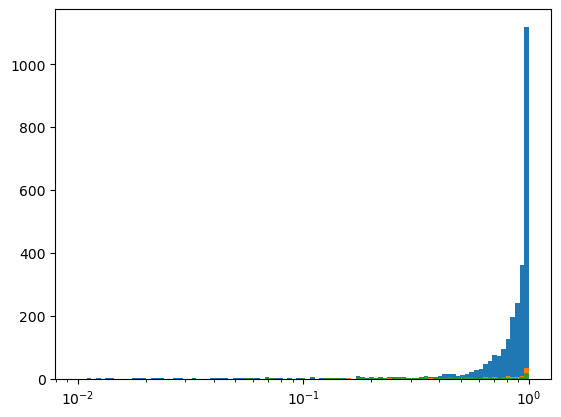

/state/partition1/job-19956442/ipykernel_625423/3311366825.py:11: RuntimeWarning: invalid value encountered in divide
  plt.plot(bins[:-1],counts_b1/counts_total)


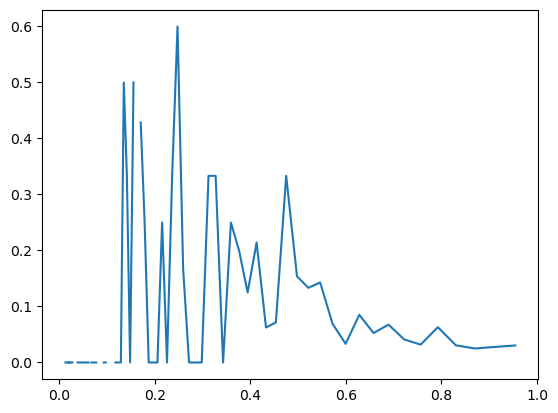

/state/partition1/job-19956442/ipykernel_625423/3311366825.py:13: RuntimeWarning: invalid value encountered in divide
  plt.plot(bins[:-1],counts_b2/counts_total)


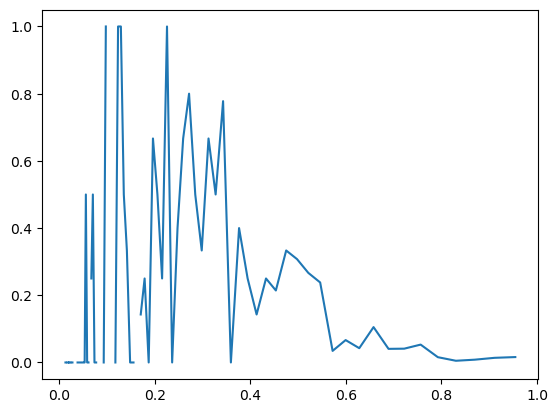

In [24]:
bins = 10**(np.linspace(-2,0,100))

counts_total, _, _ = plt.hist(reweight.flatten(),bins=bins)
counts_b1, _, _ = plt.hist(reweight[bad_both_ind[:,0],bad_both_ind[:,1]].flatten(),bins=bins)

counts_b2, _, _ = plt.hist(reweight[bad_both_ind_2[:,0],bad_both_ind_2[:,1]].flatten(),bins=bins)
plt.xscale('log')
# plt.yscale('log')
plt.show()

plt.plot(bins[:-1],counts_b1/counts_total)
plt.show()
plt.plot(bins[:-1],counts_b2/counts_total)
plt.show()